# 07 · Le réseau de similarité des Pokémon

L'idée : on décrit chaque Pokémon par un **vecteur** (ses types, ses stats, son gabarit, sa forme, ses couleurs), on relie chaque Pokémon à ceux qui lui ressemblent le plus (**graphe des k plus proches voisins**, comme au TP4), puis on analyse ce graphe avec les outils du TP3 : communautés (Louvain), centralités, comparaison avec un graphe aléatoire.

La question derrière : **est-ce que la place d'un Pokémon dans ce réseau dit quelque chose de sa popularité ?** Par exemple, un Pokémon « unique » (peu de voisins proches) est-il plus aimé qu'un Pokémon qui ressemble à plein d'autres ? Les Pokémon populaires se ressemblent-ils entre eux ?

Enfin on fait un **node2vec** (marches aléatoires + Word2Vec, comme au TP4) et un **t-SNE** pour avoir une carte 2D du réseau.

Pour la popularité, on reste sur ce qu'on a fait dans les notebooks 01 et 02 : pas de score combiné, chaque source est regardée à part, en percentile.

In [1]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from networkx.algorithms.community import louvain_communities, modularity
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE, trustworthiness

pd.set_option("display.max_columns", 50)
SEED = 0   # graine fixe pour que les résultats soient reproductibles
OUT = Path("../data/processed")
table = pd.read_csv(OUT / "table_maitre.csv", index_col="dex")
couleurs = pd.read_csv(OUT / "couleurs_sprites.csv", index_col="dex")
pop = pd.read_csv(OUT / "popularite_sources.csv", index_col="dex")
sur = pd.read_csv(OUT / "sur_sous_cotes.csv", index_col="dex")
print(table.shape, couleurs.shape, pop.shape, sur.shape)

(1025, 35) (1025, 15) (1025, 19) (1025, 13)


## 1. Le vecteur de chaque Pokémon

On décrit chaque Pokémon par **6 blocs** de variables, qui parlent uniquement de son apparence et de son rôle en jeu :
- **types** : une colonne par type (18), qui vaut 1 si le Pokémon a ce type, en premier ou en second ;
- **stats** : les 6 statistiques de combat ;
- **gabarit** : taille et poids, en log (le poids va de 0,1 kg à 999,9 kg, sans le log quelques géants écraseraient tout) ;
- **couleur officielle** (PokéAPI) en indicatrices ;
- **forme du corps** (PokéAPI) en indicatrices ;
- **couleurs de l'image** (notebook 03, sans le contour noir) : nombre de couleurs, saturation et luminosité, teinte dominante.

On a hésité pour la couleur officielle et la forme du corps, parce que ce sont des étiquettes un peu grossières. On décide quand même de **les garder** : ce sont des attributs de design, exactement ce qu'on veut comparer, et la forme du corps est la seule info qu'on a sur la silhouette du Pokémon. On verra plus bas qu'elles pèsent beaucoup dans les communautés.

On ne met **pas** la génération, le stade, starter ou légendaire, ni la popularité : on veut un réseau de ressemblance « physique », pour ensuite regarder comment la popularité s'y répartit. Si on mettait la popularité dedans, on retrouverait forcément des voisins populaires, et ça ne voudrait rien dire.

In [2]:
# types : un Pokémon peut en avoir deux
types = pd.get_dummies(table["type1"]).astype(int).add(pd.get_dummies(table["type2"]).astype(int).reindex(columns=pd.get_dummies(table["type1"]).columns, fill_value=0), fill_value=0)
print("types :", types.shape, "| valeurs :", np.unique(types.values))
stats = table[["pv", "attaque", "defense", "attaque_spe", "defense_spe", "vitesse"]]
gabarit = np.log(table[["taille_m", "poids_kg"]]).add_prefix("log_")
couleur_off = pd.get_dummies(table["couleur"], prefix="coul").astype(int)
forme = pd.get_dummies(table["forme_corps"], prefix="forme").astype(int)
# la teinte est un angle (0° = 360° = rouge) : on la passe en cosinus et sinus pour que 359° soit proche de 1°
t = np.deg2rad(couleurs["dom_teinte"])
sprite = pd.DataFrame({"nb_couleurs": couleurs["nb_couleurs"], "sat_moy": couleurs["saturation_moyenne"],
                       "lum_moy": couleurs["luminosite_moyenne"], "dom_sat": couleurs["dom_saturation"],
                       "teinte_cos": np.cos(t), "teinte_sin": np.sin(t)})
blocs = {"types": types, "stats": stats, "gabarit": gabarit, "couleur_off": couleur_off, "forme": forme, "sprite": sprite}
for nom, b in blocs.items():
    print(f"{nom:12s} {b.shape[1]:3d} colonnes | manquants : {b.isna().sum().sum()}")

types : (1025, 18) | valeurs : [0 1]
types         18 colonnes | manquants : 0
stats          6 colonnes | manquants : 0
gabarit        2 colonnes | manquants : 0
couleur_off   10 colonnes | manquants : 0
forme         14 colonnes | manquants : 0
sprite         6 colonnes | manquants : 0


On a 56 colonnes en tout, réparties en 6 blocs, et aucun manquant. Les types valent bien 0 ou 1 (un Pokémon n'a jamais deux fois le même type).

**Pondération.** Si on colle les blocs tels quels, le bloc qui a le plus de colonnes (les 18 types) pèse beaucoup plus que le gabarit (2 colonnes). On n'a pas de raison de dire que le type compte plus que la taille pour juger si deux Pokémon se ressemblent, donc on décide de donner **le même poids à chaque bloc** :
1. on **standardise** chaque colonne (moyenne 0, écart-type 1), comme au TP2 ;
2. on divise chaque bloc par la racine de son nombre de colonnes, pour que chaque bloc ait le même poids total dans la distance.

In [3]:
parties = []
for nom, b in blocs.items():
    z = StandardScaler().fit_transform(b.astype(float))
    parties.append(pd.DataFrame(z / np.sqrt(b.shape[1]), index=b.index, columns=[f"{nom}:{c}" for c in b.columns]))
X = pd.concat(parties, axis=1).loc[table.index]
print(X.shape)
# vérification : la variance totale de chaque bloc
X.var(ddof=0).groupby(X.columns.str.split(":").str[0]).sum().round(2)

(1025, 56)


couleur_off    1.0
forme          1.0
gabarit        1.0
sprite         1.0
stats          1.0
types          1.0
dtype: float64

Après la pondération, chaque bloc a bien une variance totale de 1 : aucun bloc ne domine juste parce qu'il a plus de colonnes.

### Ce qu'on a fait et pourquoi

**1. Décrire chaque Pokémon par un vecteur.** Pour construire un réseau de ressemblance, il faut d'abord pouvoir dire « à quel point deux Pokémon se ressemblent ». On a donc mis chaque Pokémon sous forme d'un vecteur de 56 nombres qui décrivent son apparence et son rôle en jeu (types, stats, gabarit, couleur, forme, couleurs de l'image).

**2. Ne pas mettre la popularité (ni la génération) dedans.** Le but, c'est de regarder ensuite comment la popularité se répartit dans le réseau. Si la popularité était dans le vecteur, les Pokémon populaires seraient forcément voisins entre eux, et le résultat serait truqué d'avance.

**3. Les indicatrices et la teinte en cosinus/sinus.** Les variables qualitatives (types, couleur officielle, forme) sont passées en colonnes 0/1, parce qu'un calcul de distance ne sait pas comparer du texte. Pour la teinte, on a utilisé le cosinus et le sinus de l'angle : sinon 359° et 1° (deux rouges) seraient vus comme les plus éloignés possibles.

**4. Le log pour le gabarit.** Comme dans le notebook 06, la taille et le poids vont de minuscules à gigantesques, donc on passe en log pour que quelques géants ne dominent pas la distance.

**5. Standardiser, puis donner le même poids à chaque bloc.** On standardise chaque colonne (comme au TP2) pour qu'aucune unité ne domine. Mais ça ne suffit pas : le bloc des types a 18 colonnes et le gabarit 2, donc les types pèseraient 9 fois plus dans la distance. On divise chaque bloc par la racine de son nombre de colonnes pour que chaque bloc ait la même variance totale. On l'a vérifié dans la cellule juste au-dessus. On n'avait aucune raison de dire qu'un bloc compte plus qu'un autre, donc on les a mis à égalité.

## 2. Le graphe des k plus proches voisins

On mesure la ressemblance avec la **similarité cosinus** (comme au TP4). Chaque Pokémon est relié à ses k plus proches voisins ; si A est dans les voisins de B ou B dans ceux de A, on met une arête (le graphe est non orienté), avec un poids égal à la similarité.

D'abord, l'effet de k sur le graphe :

In [4]:
nn = NearestNeighbors(metric="cosine").fit(X.values)
dist, idx = nn.kneighbors(X.values, n_neighbors=31)
noeuds = X.index.to_numpy()

def graphe_knn(k):
    G = nx.Graph()
    G.add_nodes_from(noeuds)
    for i in range(len(noeuds)):
        for j, d in zip(idx[i, 1:k + 1], dist[i, 1:k + 1]):
            G.add_edge(noeuds[i], noeuds[j], weight=1 - d)
    return G

lignes = []
for k in [2, 3, 5, 8, 10, 15, 20, 30]:
    g = graphe_knn(k)
    cc = list(nx.connected_components(g))
    lignes.append({"k": k, "aretes": g.number_of_edges(), "composantes": len(cc),
                   "taille plus grande": max(map(len, cc)), "degre moyen": 2 * g.number_of_edges() / g.number_of_nodes()})
effet_k = pd.DataFrame(lignes)
effet_k.set_index("k").round(1)

,aretes,composantes,taille plus grande,degre moyen
k,,,,
2,1509,3,1010,2.9
3,2228,1,1025,4.3
5,3601,1,1025,7.0
8,5673,1,1025,11.1
10,7017,1,1025,13.7
15,10332,1,1025,20.2
20,13546,1,1025,26.4
30,20008,1,1025,39.0


Avec k = 2, le graphe est coupé en 3 morceaux. Dès k = 3, tous les Pokémon sont dans une seule composante. Plus k augmente, plus il y a d'arêtes.

On choisit **k = 10**. Avec moins (3 à 5), le graphe est connexe mais très « maigre » : un Pokémon n'a que quelques voisins, et une seule ressemblance un peu bizarre change beaucoup sa place. Avec beaucoup plus (20, 30), on relie des Pokémon qui ne se ressemblent plus vraiment et les groupes se mélangent. 10, c'est le même ordre de grandeur que ce qu'on a utilisé au TP4. Avec k = 10, chaque Pokémon a en moyenne 13,7 voisins (plus que 10, parce qu'on garde aussi l'arête quand A a choisi B mais pas l'inverse).

In [5]:
K = 10
G = graphe_knn(K)
for n in G:
    G.nodes[n]["nom"] = table.loc[n, "nom_fr"]
print(G)
degres = pd.Series(dict(G.degree()))
degres.describe()

Graph with 1025 nodes and 7017 edges


count    1025.000000
mean       13.691707
std         3.949953
min        10.000000
25%        11.000000
50%        12.000000
75%        15.000000
max        31.000000
dtype: float64

Le graphe final a 1 025 nœuds et 7 017 arêtes. Le degré va de 10 (le minimum, ses 10 propres voisins) à 31.

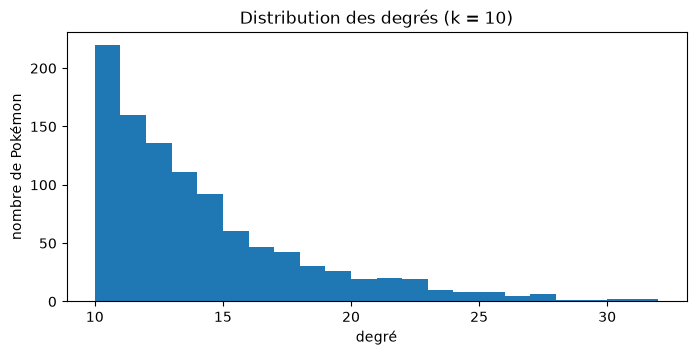

Pokémon les plus « connectés » :


Carapuce      31
Galeking      31
Aligatueur    30
Ama-Ama       30
Melmetal      29
Palkia        28
Maganon       27
Ponchiot      27
Korillon      27
Groudon       27
dtype: int64

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(degres, bins=range(degres.min(), degres.max() + 2))
ax.set_xlabel("degré"); ax.set_ylabel("nombre de Pokémon")
ax.set_title(f"Distribution des degrés (k = {K})")
plt.show()
print("Pokémon les plus « connectés » :")
degres.sort_values(ascending=False).head(10).rename(table["nom_fr"])

Les Pokémon avec le plus de voisins (Carapuce, Miraidon, Ama-Ama, Melmetal…) ressemblent à beaucoup d'autres : ils sont choisis comme voisins par plein de Pokémon.

In [7]:
# les voisins de quelques Pokémon connus : est-ce que le graphe a du sens ?
for d in [6, 25, 94, 133, 448]:
    v = sorted(G[d], key=lambda n: -G[d][n]["weight"])[:6]
    print(f"{table.loc[d, 'nom_fr']:12s} →", ", ".join(table.loc[v, "nom_fr"]))

Dracaufeu    → Magmar, Goupelin, Aflamanoir, Maganon, Braségali, Ho-Oh
Pikachu      → Pohm, Pichu, Posipi, Voltoutou, Négapi, Élekid
Ectoplasma   → Nidoking, Salarsen, Mewtwo, Wimessir, Magirêve, Mandrillon
Évoli        → Ponchiot, Manglouton, Keunotor, Ratentif, Laporeille, Rattatac
Lucario      → Pingoléon, Cobaltium, Lézargus, Charkos, Karaclée, Riolu


Les voisins ont du sens : Dracaufeu est entouré de Pokémon Feu rouges et dressés (Maganon, Magmar, Goupelin, Braségali), Pikachu de petits Pokémon Électrik jaunes (Pohm, Pichu, Posipi, Voltoutou, Négapi), Lucario de Pokémon Combat/Acier dressés (Pingoléon, Cobaltium, Riolu). Évoli, lui, est mis avec des petits mammifères marron (Ponchiot, Keunotor, Ratentif…) : le réseau ne voit que l'apparence, pas la popularité.

### Comparaison avec un graphe aléatoire de même taille (comme au TP3)

In [8]:
n, m = G.number_of_nodes(), G.number_of_edges()
rand = nx.gnm_random_graph(n, m, seed=SEED)
def resume(g):
    cc = g.subgraph(max(nx.connected_components(g), key=len))
    return [g.number_of_nodes(), g.number_of_edges(), nx.density(g), nx.transitivity(g), nx.average_clustering(g),
            cc.number_of_nodes(), nx.average_shortest_path_length(cc), nx.diameter(cc)]
comparaison = pd.DataFrame({"Pokémon (kNN)": resume(G), "Aléatoire G(n,m)": resume(rand)},
    index=["nœuds", "arêtes", "densité", "transitivité", "clustering moyen", "taille LCC", "plus court chemin moyen (LCC)", "diamètre (LCC)"])
comparaison.round(3)

,Pokémon (kNN),"Aléatoire G(n,m)"
nœuds,1025.000,1025.000
arêtes,7017.000,7017.000
densité,0.013,0.013
transitivité,0.316,0.014
clustering moyen,0.326,0.014
taille LCC,1025.000,1025.000
plus court chemin moyen (LCC),3.705,2.910
diamètre (LCC),6.000,5.000


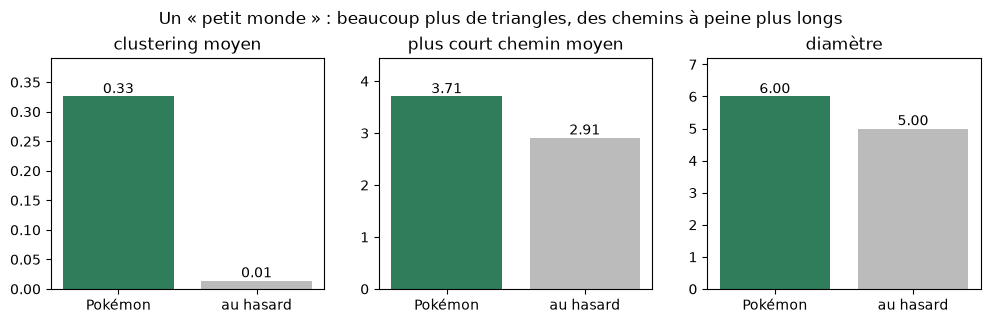

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, ligne, titre in zip(axes, ["clustering moyen", "plus court chemin moyen (LCC)", "diamètre (LCC)"],
                            ["clustering moyen", "plus court chemin moyen", "diamètre"]):
    v = comparaison.loc[ligne]
    ax.bar(["Pokémon", "au hasard"], v.values, color=["#2f7d5b", "#bbbbbb"])
    for x, y in enumerate(v.values): ax.text(x, y, f"{y:.2f}" if y < 10 else f"{y:.0f}", ha="center", va="bottom")
    ax.set_title(titre); ax.set_ylim(0, v.max() * 1.2)
fig.suptitle("Un « petit monde » : beaucoup plus de triangles, des chemins à peine plus longs", y=1.04)
plt.show()

Comparé à un graphe aléatoire de même taille, notre graphe a un **clustering bien plus fort** (0,33 contre 0,01) : les voisins d'un Pokémon se ressemblent aussi entre eux, il y a des « familles ». Les chemins sont un peu plus longs (3,7 contre 2,9, diamètre 6 contre 5), ce qui est normal pour un graphe de similarité, mais ça reste court : on va de n'importe quel Pokémon à n'importe quel autre en moins de 4 étapes en moyenne.

### Ce qu'on a fait et pourquoi

**1. La similarité cosinus.** On compare la **direction** des vecteurs plutôt que leur longueur, comme au TP4. Deux Pokémon qui ont le même « profil » (mêmes blocs au-dessus ou en dessous de la moyenne) sont proches, même si l'un est un peu plus extrême que l'autre.

**2. Un graphe des k plus proches voisins plutôt qu'un seuil.** On aurait pu relier tous les couples au-dessus d'une similarité fixe, mais alors certains Pokémon très « à part » n'auraient aucun voisin, et les zones denses auraient des centaines d'arêtes. Avec les k plus proches voisins, chaque Pokémon a au moins k voisins. On a symétrisé (une arête si A choisit B **ou** B choisit A) pour avoir un graphe non orienté, ce que demandent Louvain et la plupart des centralités.

**3. Le choix de k.** On a fait un tableau de l'effet de k (nombre de morceaux, d'arêtes, degré moyen) avant de choisir. Trop petit, le graphe est coupé ou fragile (une seule ressemblance bizarre change tout) ; trop grand, on relie des Pokémon qui ne se ressemblent plus. On a pris k = 10, assez pour que le graphe soit d'un seul morceau et stable, et du même ordre qu'au TP4.

**4. L'histogramme des degrés et les voisins de Pokémon connus.** L'histogramme montre comment les arêtes sont réparties (est-ce que quelques Pokémon sont des « hubs » ?). Regarder les voisins de Dracaufeu, Pikachu, Évoli… c'est notre test de bon sens : si les voisins n'avaient aucun sens, tout le reste de l'analyse ne vaudrait rien.

**5. La comparaison avec un graphe aléatoire de même taille (TP3).** Un chiffre comme « clustering = 0,3 » ne veut rien dire tout seul. On le compare à un graphe aléatoire G(n, m) avec autant de nœuds et d'arêtes : si notre graphe a beaucoup plus de clustering, c'est qu'il y a de vraies « familles » de Pokémon, et pas juste l'effet du nombre d'arêtes.

## 3. Les communautés (Louvain)

Comme au TP3/TP4, on cherche des groupes de Pokémon très reliés entre eux et peu reliés au reste, avec l'algorithme de **Louvain** (pondéré par la similarité). La **modularité** dit si le découpage est meilleur qu'un découpage au hasard (0 = pas mieux, plus c'est proche de 1 plus les groupes sont nets).

Louvain a une part de hasard : on le relance avec plusieurs graines pour voir si le résultat est stable.

nombre de communautés : [15, 15, 14, 15, 15, 14, 14, 17, 14, 14]
modularité : [np.float64(0.714), np.float64(0.711), np.float64(0.712), np.float64(0.717), np.float64(0.717), np.float64(0.715), np.float64(0.713), np.float64(0.715), np.float64(0.715), np.float64(0.715)]
accord avec la graine 0 (ARI) : min 0.81 | moyenne 0.85


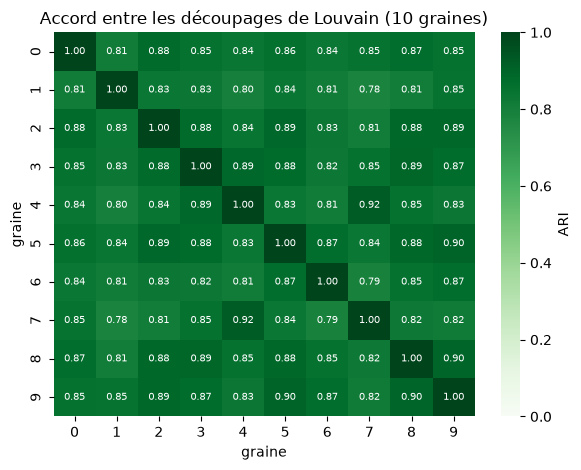

In [10]:
from sklearn.metrics import adjusted_rand_score
essais = {s: louvain_communities(G, weight="weight", seed=s) for s in range(10)}
def etiquettes(comms):
    lab = {}
    for i, c in enumerate(sorted(comms, key=len, reverse=True)):
        for n in c:
            lab[n] = i
    return pd.Series(lab).sort_index()
labs = {s: etiquettes(c) for s, c in essais.items()}
print("nombre de communautés :", [len(c) for c in essais.values()])
print("modularité :", [round(modularity(G, c, weight="weight"), 3) for c in essais.values()])
ari = [adjusted_rand_score(labs[0], labs[s]) for s in range(1, 10)]
print("accord avec la graine 0 (ARI) : min", round(min(ari), 2), "| moyenne", round(np.mean(ari), 2))
ari_mat = pd.DataFrame([[adjusted_rand_score(labs[a], labs[b]) for b in range(10)] for a in range(10)])
fig, ax = plt.subplots(figsize=(6, 4.8))
sns.heatmap(ari_mat, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1, annot_kws={"size": 7},
            cbar_kws={"label": "ARI"}, ax=ax)
ax.set_xlabel("graine"); ax.set_ylabel("graine"); ax.set_title("Accord entre les découpages de Louvain (10 graines)")
plt.tight_layout(); plt.show()

Louvain trouve entre 14 et 17 communautés selon la graine, avec une modularité toujours autour de **0,71-0,72**. Les découpages se ressemblent bien d'une graine à l'autre (ARI moyen 0,85, au pire 0,81), donc le résultat est assez stable : ce sont surtout quelques petits groupes qui sont coupés ou fusionnés différemment.

Comme les graines donnent à peu près le même résultat, on décide simplement de **garder la graine 0** pour la suite, pour que tout soit reproductible.

In [11]:
communautes = essais[SEED]
comm = labs[SEED].rename("communaute")
print(f"{len(communautes)} communautés, modularité = {modularity(G, communautes, weight='weight'):.3f}")
comm.value_counts().sort_index()

15 communautés, modularité = 0.714


communaute
0     115
1     106
2     101
3      96
4      91
5      91
6      89
7      72
8      56
9      47
10     44
11     39
12     36
13     22
14     20
Name: count, dtype: int64

Avec la graine 0 : 15 communautés, de 20 à 115 Pokémon.

In [12]:
# modularité d'un graphe aléatoire de même taille, pour comparer
mod_rand = modularity(rand, louvain_communities(rand, seed=SEED))
print("modularité Louvain sur le graphe aléatoire :", round(mod_rand, 3))

modularité Louvain sur le graphe aléatoire : 0.226


Sur un graphe aléatoire, Louvain n'arrive qu'à 0,23 de modularité. Les communautés de notre graphe sont donc bien réelles.

### Qui est dans chaque communauté ?

In [13]:
d = table.join(comm)
def top(s, n=3):
    v = s.value_counts(normalize=True).head(n)
    return ", ".join(f"{k} {p:.0%}" for k, p in v.items())
desc = d.groupby("communaute").agg(
    n=("nom_fr", "size"),
    types=("type1", lambda s: top(pd.concat([s, d.loc[s.index, "type2"].dropna()]))),
    couleur=("couleur", top),
    forme=("forme_corps", lambda s: top(s, 2)),
    poids_median=("poids_kg", "median"),
    total_stats_moyen=("total_stats", "mean"),
    exemples=("nom_fr", lambda s: ", ".join(s.loc[d.loc[s.index, "total_stats"].sort_values(ascending=False).index[:4]])),
)
desc.round(1)

,n,types,couleur,forme,poids_median,total_stats_moyen,exemples
communaute,,,,,,,
0,115,"grass 41%, dragon 11%, poison 7%","green 90%, blue 3%, purple 3%","humanoid 24%, upright 24%",22.0,439.4,"Rayquaza, Celebi, Tyranocif, Shaymin"
1,106,"water 33%, dragon 9%, psychic 8%","blue 93%, white 3%, purple 3%","upright 41%, quadruped 19%",41.3,462.1,"Éthernatos, Dialga, Lunala, Xerneas"
2,101,"poison 15%, ghost 14%, psychic 12%","purple 67%, green 8%, gray 6%","ball 38%, upright 14%",11.5,407.2,"Mewtwo, Palkia, Muplodocus, Genesect"
3,96,"ice 15%, fairy 11%, normal 9%","white 77%, blue 8%, gray 5%","quadruped 22%, heads 17%",32.8,436.3,"Arceus, Lugia, Solgaleo, Reshiram"
4,91,"steel 16%, rock 11%, normal 11%","gray 92%, purple 3%, blue 2%","quadruped 34%, upright 23%",60.0,454.2,"Kyurem, Melmetal, Ékaïser, Glaivodo"
5,91,"normal 27%, ground 18%, fire 9%","brown 99%, red 1%","quadruped 54%, upright 25%",34.5,416.9,"Monaflèmit, Heatran, Volcanion, Démétéros"
6,89,"fire 28%, fighting 10%, flying 8%","red 75%, blue 10%, brown 7%","upright 33%, tentacles 25%",39.0,461.9,"Ho-Oh, Yveltal, Groudon, Koraidon"
7,72,"electric 28%, psychic 11%, fire 9%",yellow 100%,"quadruped 29%, upright 26%",23.8,436.8,"Victini, Zeraora, Jirachi, Ire-Foudre"
8,56,"fairy 26%, psychic 19%, normal 18%",pink 100%,"humanoid 34%, upright 30%",14.4,405.8,"Mew, Diancie, Créfollet, Amovénus"


Les communautés se lisent assez facilement, et elles suivent surtout **la couleur officielle et la forme du corps** :
- la plupart sont presque d'une seule couleur : jaune à 100 % (7, avec beaucoup d'Électrik), rose à 100 % (8, Fée/Psy), marron à 99 % (5), bleue à 93 % (1, Eau), grise à 92 % (4, Acier/Roche), verte à 90 % (0, Plante), noire à 89 % (9 : Giratina, Zekrom, Darkrai, Necrozma…), blanche à 77 % (3), rouge à 75 % (6, Feu), violette à 67 % (2, Poison/Spectre) ;
- d'autres sont définies par une forme : 95 % « armure » (11, Insectes et crustacés à carapace), 100 % « poisson » (12, Lokhlass, Oratoria…), 100 % « ailes d'insecte » (13), 100 % « pattes » (14) et 77 % « ailes » (10, les oiseaux).

C'est ce qu'on avait prévu en gardant ces deux variables : comme un Pokémon n'a qu'une couleur officielle et qu'une forme, ces indicatrices sont très « tranchantes » dans la distance. Les communautés sont donc surtout des familles de couleur et de silhouette, ce qui reste une façon raisonnable de grouper des designs.

*Remarque : les petites communautés dépendent des détails des données. Avec les versions précédentes des couleurs du notebook 03, Louvain trouvait 13 communautés (les oiseaux et les Pokémon noirs ensemble), puis 14 ; depuis que le contour est enlevé avant le k-means, les poissons forment aussi leur propre groupe. Les grandes familles de couleur, elles, restent les mêmes.*

In [14]:
# un nom pour chaque communauté, d'après le tableau ci-dessus (couleur ou forme qui domine).
# Les numéros viennent de Louvain : si les données changent, la numérotation peut changer aussi, d'où le contrôle.
noms_comm = {0: "vert · Plante", 1: "bleu · Eau", 2: "violet · Poison/Spectre", 3: "blanc",
             4: "gris · Acier/Roche", 5: "marron · quadrupèdes", 6: "rouge · Feu", 7: "jaune · Électrik",
             8: "rose · Fée/Psy", 9: "noir", 10: "ailes", 11: "carapaces", 12: "poissons",
             13: "ailes d'insecte", 14: "pattes"}
assert set(noms_comm) == set(comm.unique()), "le nombre de communautés a changé : relire le tableau ci-dessus et renommer"
# une couleur d'affichage par communauté : sa couleur officielle dominante,
# sauf pour les communautés définies par une forme (75 % ou plus de la même forme), en gris neutre
PALETTE = {"green": "#5bb85c", "blue": "#4a90c2", "purple": "#9b6bb8", "white": "#eeeeee", "gray": "#a0a0a0",
           "brown": "#a0785a", "red": "#d9534f", "yellow": "#f2d13c", "pink": "#f29bc1", "black": "#444444"}
COUL_COMM = {noms_comm[c]: "#d9d4c7" if (d.loc[d.communaute == c, "forme_corps"].value_counts(normalize=True).iloc[0] >= .75)
             else PALETTE[d.loc[d.communaute == c, "couleur"].mode()[0]] for c in noms_comm}

from PIL import Image
SPRITES = Path("../data/raw/sprites/official_artwork")
def sprite_img(dx, taille=96):
    im = Image.open(SPRITES / f"{dx}.png").convert("RGBA")
    im.thumbnail((taille, taille))
    return im

Pour voir à quoi ressemble chaque communauté, on affiche ses **8 Pokémon les plus typiques** : ceux qui ont le plus de liens (pondérés par la similarité) à l'intérieur de leur communauté.

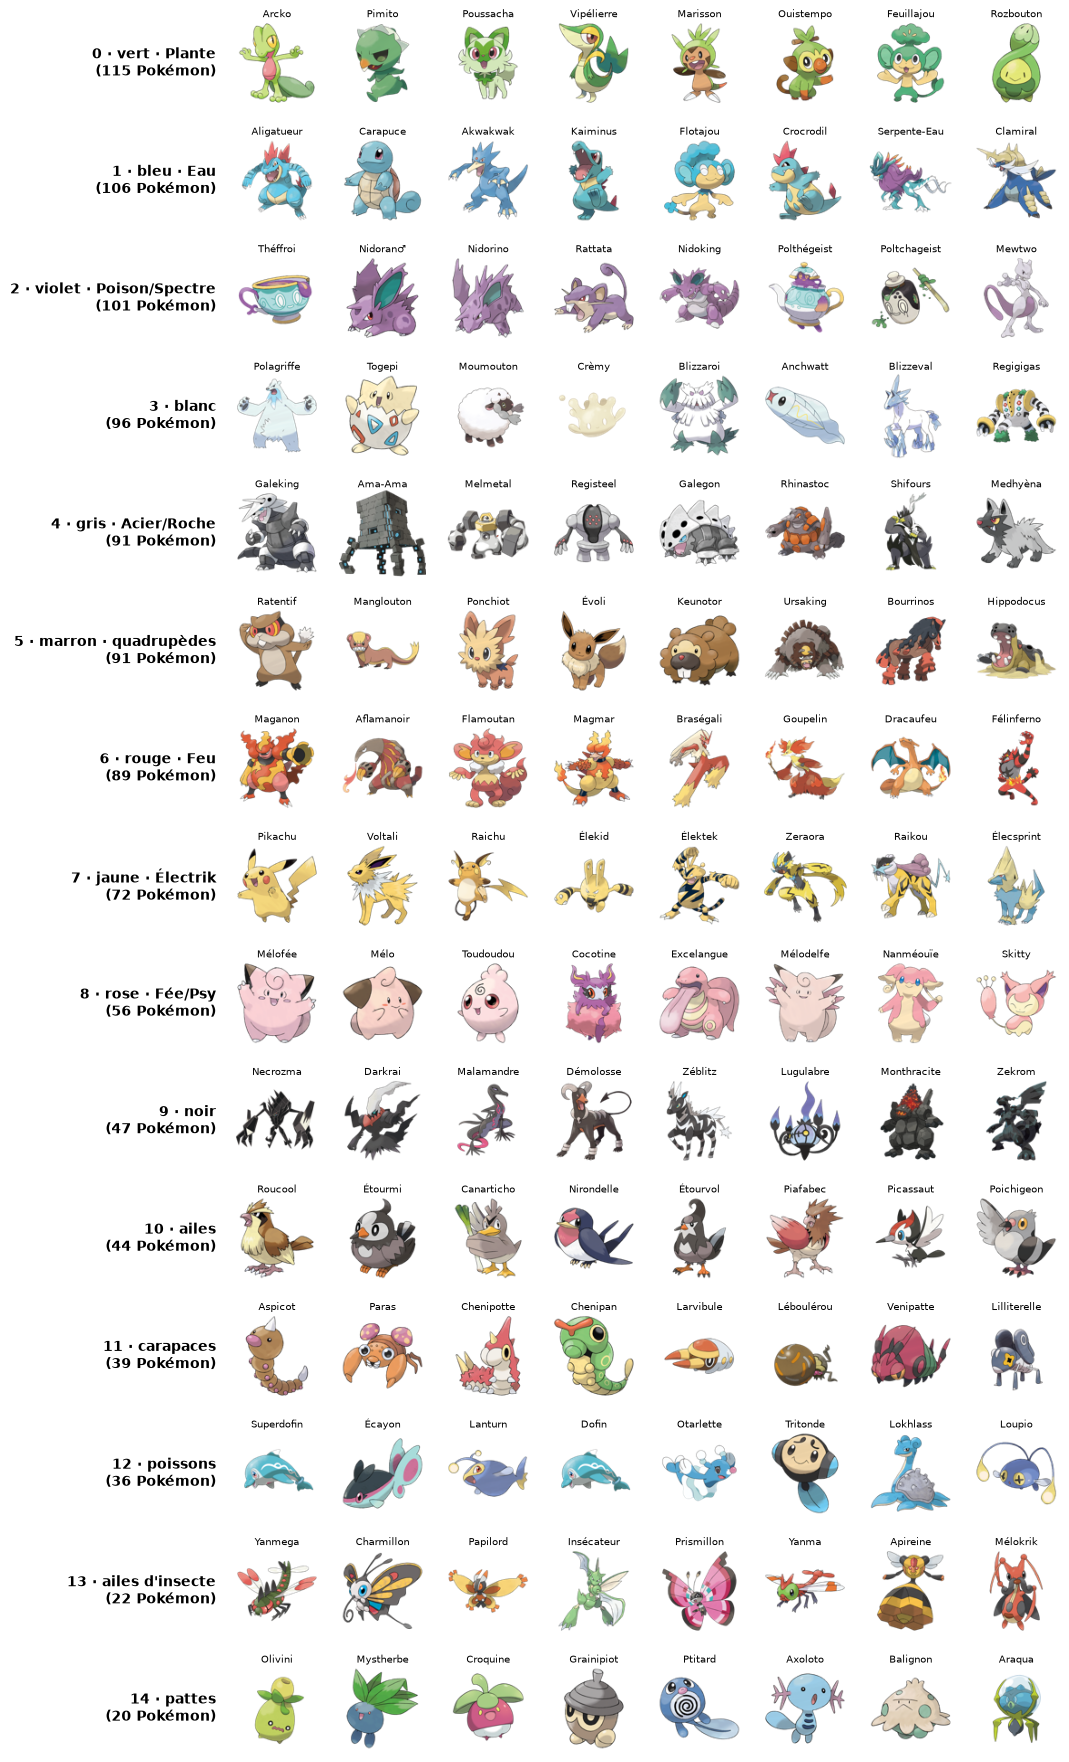

In [15]:
# les plus typiques : somme des similarités vers les membres de leur propre communauté
interne = pd.Series({n: sum(w for v, w in ((v, G[n][v]["weight"]) for v in G[n]) if comm[v] == comm[n]) for n in G})
N_IMG = 8
fig, axes = plt.subplots(len(noms_comm), N_IMG, figsize=(12, 1.5 * len(noms_comm)))
for r, c in enumerate(sorted(noms_comm)):
    membres = interne[comm.loc[interne.index] == c].nlargest(N_IMG).index
    for ax, dx in zip(axes[r], membres):
        ax.imshow(sprite_img(dx)); ax.set_title(table.loc[dx, "nom_fr"], fontsize=7, pad=1)
    for ax in axes[r]: ax.axis("off")
    axes[r, 0].text(-0.2, 0.5, f"{c} · {noms_comm[c]}\n({(comm == c).sum()} Pokémon)", transform=axes[r, 0].transAxes,
                    ha="right", va="center", fontsize=10, weight="bold")
plt.subplots_adjust(left=0.2, hspace=0.35, wspace=0.05); plt.show()

En images, les communautés se comprennent tout de suite : les starters Plante (Arcko, Vipélierre, Marisson, Ouistempo…) dans la verte, les starters Eau dans la bleue, Pikachu, Raichu et Voltali dans la jaune, les rongeurs et les petits mammifères marron (Ratentif, Évoli, Keunotor…), les légendaires sombres dans la noire (Necrozma, Darkrai, Zekrom), les oiseaux, les chenilles, les poissons… La violette est la plus mélangée : elle regroupe des Pokémon violets très différents (Théffroi, la lignée des Nidoran, Rattata, Mewtwo).

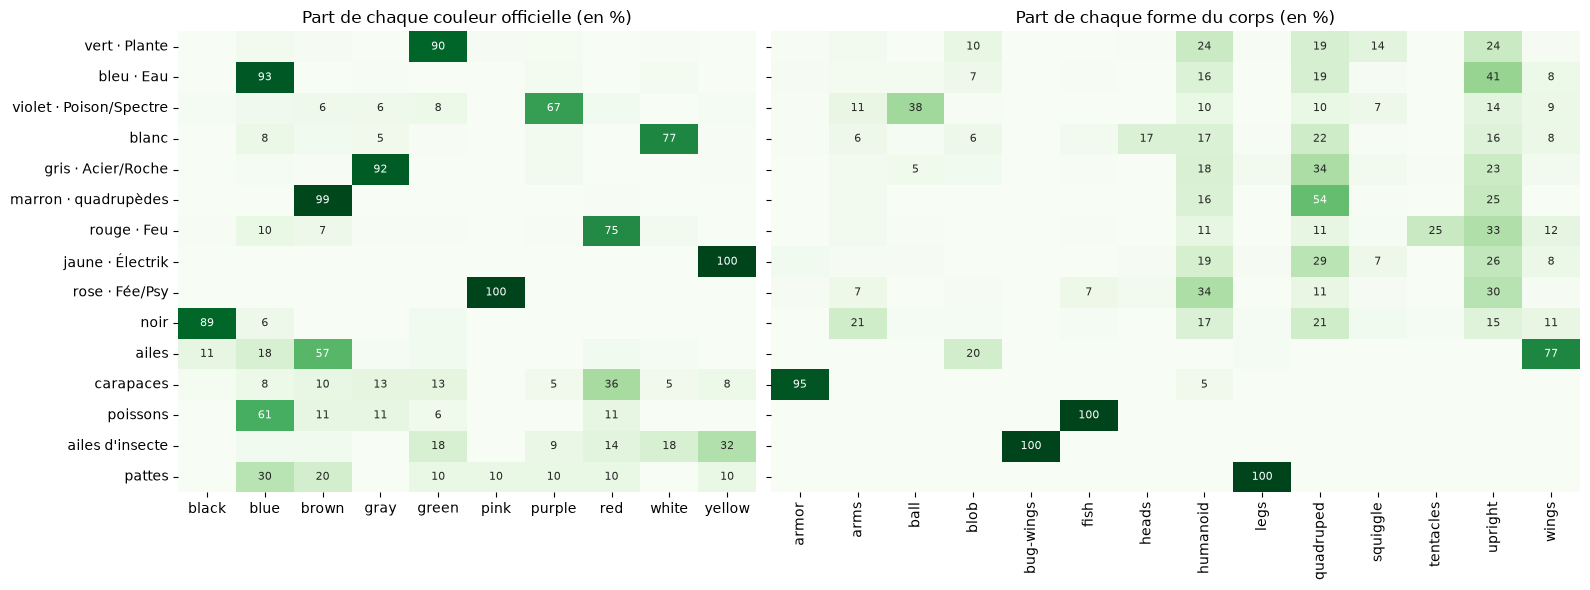

In [16]:
# la composition de chaque communauté : part de chaque couleur officielle et de chaque forme du corps
lignes_c = [noms_comm[c] for c in sorted(noms_comm)]
compo_coul = pd.crosstab(d["communaute"].map(noms_comm), d["couleur"], normalize="index").loc[lignes_c]
compo_forme = pd.crosstab(d["communaute"].map(noms_comm), d["forme_corps"], normalize="index").loc[lignes_c]
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True, gridspec_kw={"width_ratios": [10, 14]})
for ax, tabc, titre in [(axes[0], compo_coul, "couleur officielle"), (axes[1], compo_forme, "forme du corps")]:
    sns.heatmap(tabc, cmap="Greens", vmin=0, vmax=1, annot=(tabc * 100).round().astype(int).astype(str).where(tabc >= 0.05, ""),
                fmt="", cbar=False, annot_kws={"size": 8}, ax=ax)
    ax.set_title(f"Part de chaque {titre} (en %)"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

Le même constat en chiffres : à gauche, chaque communauté de « couleur » est presque d'une seule couleur officielle (une case foncée par ligne), mais avec des formes très variées (à droite, des cases claires étalées). Pour les cinq dernières, c'est l'inverse : une seule forme (armure, poisson, ailes d'insecte, pattes, ailes) et plusieurs couleurs. Les communautés se font donc **soit par la couleur, soit par la forme**, jamais par les deux à la fois.

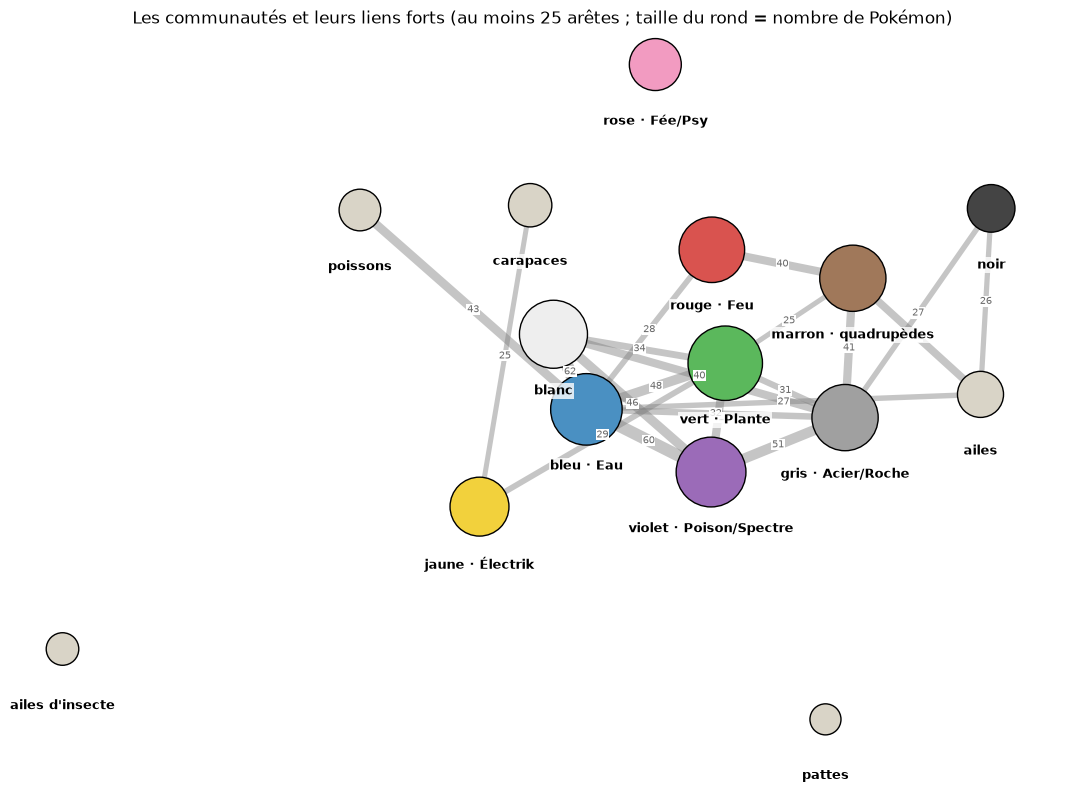

liens entre communautés les plus nombreux :
bleu · Eau — blanc                              62
bleu · Eau — violet · Poison/Spectre            60
violet · Poison/Spectre — gris · Acier/Roche    51
vert · Plante — bleu · Eau                      48
violet · Poison/Spectre — blanc                 46
bleu · Eau — poissons                           43

part des liens qui restent dans leur communauté : 78%


In [17]:
# le réseau des communautés : un rond par communauté, un trait entre deux communautés d'autant plus épais
# qu'il y a de liens entre leurs Pokémon
H = nx.Graph()
for c in noms_comm:
    H.add_node(noms_comm[c], taille=(comm == c).sum())
for u, v in G.edges():
    a, b = noms_comm[comm[u]], noms_comm[comm[v]]
    if a != b:
        H.add_edge(a, b, weight=H[a][b]["weight"] + 1 if H.has_edge(a, b) else 1)
pos = nx.spring_layout(H, weight="weight", seed=SEED, k=1.2)
SEUIL = 25   # on ne dessine que les liens forts (au moins 25 arêtes entre les deux communautés), sinon tout est relié
forts = [(u, v) for u, v, w in H.edges(data="weight") if w >= SEUIL]
fig, ax = plt.subplots(figsize=(11, 8))
larg = np.array([H[u][v]["weight"] for u, v in forts])
nx.draw_networkx_edges(H, pos, edgelist=forts, width=larg / larg.max() * 9, alpha=.45, edge_color="grey", ax=ax)
for u, v in forts:
    (x1, y1), (x2, y2) = pos[u], pos[v]
    ax.text((x1 + x2) / 2, (y1 + y2) / 2, H[u][v]["weight"], fontsize=7, color="dimgrey", ha="center", va="center",
            bbox=dict(fc="white", ec="none", pad=.5))
nx.draw_networkx_nodes(H, pos, node_size=[H.nodes[n]["taille"] * 25 for n in H], node_color=[COUL_COMM[n] for n in H],
                       edgecolors="black", ax=ax)
for n, (x, y) in pos.items():
    ax.text(x, y - 0.11, n, ha="center", va="top", fontsize=9, weight="bold", bbox=dict(fc="white", ec="none", alpha=.8, pad=1))
ax.axis("off"); ax.set_title(f"Les communautés et leurs liens forts (au moins {SEUIL} arêtes ; taille du rond = nombre de Pokémon)")
plt.tight_layout(); plt.show()
print("liens entre communautés les plus nombreux :")
print(pd.Series({f"{u} — {v}": w for u, v, w in H.edges(data="weight")}).sort_values(ascending=False).head(6).to_string())
print(f"\npart des liens qui restent dans leur communauté : {sum(G.subgraph(comm.index[comm == c]).number_of_edges() for c in noms_comm) / G.number_of_edges():.0%}")

78 % des liens restent à l'intérieur de leur communauté. Les autres relient surtout les grandes communautés de couleur entre elles, au centre (bleue–blanche, bleue–violette, violette–grise, verte–bleue) : ce sont des Pokémon qui se ressemblent par le type ou la forme mais n'ont pas la même couleur officielle. Les communautés de forme sont accrochées à une ou deux autres (les poissons à la bleue, les ailes à la grise et à la noire, les carapaces à la jaune), et trois sont presque isolées : la rose, les ailes d'insecte et les pattes n'ont aucun lien fort avec le reste.

In [18]:
# la part de chaque génération, de légendaires et de starters par communauté
extra = d.groupby("communaute").agg(gen_moyenne=("generation", "mean"), part_legendaire=("legendaire", "mean"),
                                    part_starter=("starter", "mean"), part_sans_evolution=("stade_categorie", lambda s: (s == "sans évolution").mean()))
extra.round(2)

,gen_moyenne,part_legendaire,part_starter,part_sans_evolution
communaute,,,,
0,5.24,0.06,0.21,0.21
1,4.55,0.13,0.22,0.24
2,4.26,0.05,0.00,0.19
3,5.52,0.06,0.03,0.23
4,5.42,0.08,0.01,0.19
5,4.24,0.05,0.01,0.15
6,4.92,0.09,0.21,0.24
7,4.15,0.10,0.04,0.25
8,4.43,0.05,0.00,0.23


La génération moyenne varie un peu (de 3,8 à 5,5), mais aucune communauté n'est une génération. Les starters sont surtout dans la bleue/Eau (1, 22 %), la verte/Plante (0, 21 %) et la rouge/Feu (6, 21 %), logique puisque les starters sont Plante, Feu ou Eau. La noire (9) a de loin le plus de légendaires (19 %), devant la bleue (1, 13 %).

### La popularité par communauté

Pour la popularité, on prend une mesure par source :
- **Reddit**, **Johto Times** et **Google Trends** : le percentile **dans la génération** du notebook 02, comme dans les autres notebooks. On compare ainsi chaque Pokémon aux Pokémon de sa génération, sans que l'effet génération (la nostalgie) s'en mêle : c'est important ici, parce que des Pokémon voisins dans le réseau ont souvent des générations proches. Les 28 Pokémon dont le nom anglais est aussi un mot courant (Persian, Electrode, Ditto…) n'ont pas de valeur Google (997 Pokémon sur 1 025), mais ils restent dans les sondages ;
- **Pokémon of the Year 2020** : publié (dans le top 30 de sa région) ou non, pour les 890 Pokémon votables.

On regarde aussi les **résidus** du notebook 05 (ce qui reste de la popularité une fois retirés génération, stade, starter par stade, légendaire et type), pour voir si un effet de communauté passe juste par ces effets attendus.

Pour chaque mesure, on fait un test de **Kruskal-Wallis** : est-ce que la popularité diffère entre les communautés ? (C'est la version non paramétrique de l'ANOVA, adaptée à des percentiles qui ne sont pas normaux.)

In [19]:
from scipy.stats import kruskal
popcols = {"reddit": "reddit_pct_gen", "johto": "johto_pct_gen", "trends": "trends_pct_gen"}
dp = pop[list(popcols.values())].rename(columns={v: k for k, v in popcols.items()}).join(
     sur[["resid_reddit", "resid_johto", "resid_trends"]]).join(comm)
# Pokémon of the Year : publié (1) ou non (0), pour les 890 Pokémon votables seulement.
# Attention : on publie 30 Pokémon par région, donc la part de publiés vaut à peu près 30 / taille de la génération
# (notebook 06). Comme pour les percentiles, on se place DANS la génération : on retire à chaque Pokémon le taux de
# publication de sa génération. dp["poty"] = publié - attendu (positif = publié plus souvent qu'attendu).
publie = pd.Series(np.where(dp.index <= 890, table["poty_votes"].notna().astype(float), np.nan), index=dp.index)
attendu_poty = publie.groupby(table["generation"]).transform("mean")
dp["poty"] = publie - attendu_poty
moy = dp.groupby("communaute").mean().round(2)
moy["n"] = comm.value_counts().sort_index()
display(moy)
kw = []
for c in ["reddit", "johto", "trends", "resid_reddit", "resid_johto", "resid_trends"]:
    groupes = [g[c].dropna() for _, g in dp.groupby("communaute")]
    h, p = kruskal(*groupes)
    kw.append({"mesure": c, "p_valeur": p})
    print(f"{c:13s} Kruskal-Wallis H = {h:6.1f}  p = {p:.2g}")

# pour Pokémon of the Year (oui / non), on teste la communauté À GÉNÉRATION FIXÉE : régression logistique
# publié ~ génération, puis publié ~ génération + communauté, et test du rapport de vraisemblance
import statsmodels.formula.api as smf
from scipy.stats import chi2 as loi_chi2
dlog = pd.DataFrame({"publie": publie, "generation": table["generation"], "communaute": dp["communaute"]}).dropna()
m0 = smf.logit("publie ~ C(generation)", dlog).fit(disp=0)
m1 = smf.logit("publie ~ C(generation) + C(communaute)", dlog).fit(disp=0)
lr = 2 * (m1.llf - m0.llf); ddl = m1.df_model - m0.df_model
p_poty = loi_chi2.sf(lr, ddl)
kw.append({"mesure": "poty", "p_valeur": p_poty})
print(f"poty          rapport de vraisemblance = {lr:5.1f} ({ddl:.0f} ddl)  p = {p_poty:.2g}  (à génération fixée)")

# publiés observés contre attendus vu la composition de la communauté par génération
poty_comm = pd.DataFrame({"publies": publie.groupby(dp["communaute"]).sum(),
                          "attendus": attendu_poty.where(publie.notna()).groupby(dp["communaute"]).sum(),
                          "votables": publie.groupby(dp["communaute"]).count()})
poty_comm["part_observee"] = poty_comm.publies / poty_comm.votables
poty_comm["part_attendue"] = poty_comm.attendus / poty_comm.votables
poty_comm["obs_sur_att"] = poty_comm.publies / poty_comm.attendus
poty_comm.round(2)

,reddit,johto,trends,resid_reddit,resid_johto,resid_trends,poty,n
communaute,,,,,,,,
0,0.58,0.56,0.53,0.04,0.02,0.02,0.06,115
1,0.54,0.56,0.55,-0.00,0.01,0.01,0.12,106
2,0.45,0.47,0.51,-0.03,-0.02,0.00,-0.01,101
3,0.50,0.53,0.52,0.02,0.04,0.04,0.04,96
4,0.51,0.49,0.49,-0.00,-0.02,-0.02,0.01,91
5,0.47,0.46,0.46,0.00,-0.01,-0.01,-0.13,91
6,0.56,0.55,0.53,-0.03,-0.03,-0.03,0.04,89
7,0.60,0.61,0.61,0.05,0.06,0.02,0.10,72
8,0.40,0.43,0.46,-0.06,-0.03,-0.03,-0.14,56


reddit        Kruskal-Wallis H =   51.9  p = 3e-06
johto         Kruskal-Wallis H =   66.7  p = 7.6e-09
trends        Kruskal-Wallis H =   37.5  p = 0.00061
resid_reddit  Kruskal-Wallis H =   19.4  p = 0.15
resid_johto   Kruskal-Wallis H =   27.2  p = 0.018
resid_trends  Kruskal-Wallis H =   12.5  p = 0.57


poty          rapport de vraisemblance =  46.9 (14 ddl)  p = 2e-05  (à génération fixée)


,publies,attendus,votables,part_observee,part_attendue,obs_sur_att
communaute,,,,,,
0,32.0,26.13,96,0.33,0.27,1.22
1,37.0,25.45,94,0.39,0.27,1.45
2,24.0,25.22,93,0.26,0.27,0.95
3,28.0,24.29,83,0.34,0.29,1.15
4,19.0,17.97,70,0.27,0.26,1.06
5,11.0,22.00,82,0.13,0.27,0.50
6,25.0,21.62,79,0.32,0.27,1.16
7,22.0,15.77,62,0.35,0.25,1.40
8,7.0,13.67,49,0.14,0.28,0.51


Sur les **sondages**, la popularité diffère entre communautés (Kruskal-Wallis, p < 0,001 pour Reddit et pour le Johto Times) :
- les plus aimées : la 9 (noire, 0,64 sur Reddit et 0,59 au Johto Times), la 7 (jaune/Électrik, 0,60 à 0,61 selon la source), la 0 (verte/Plante, 0,56-0,58) et la 13 (ailes d'insecte, 0,59 au Johto Times) ;
- les moins aimées : la 11 (carapaces, 0,32 à 0,36), la 12 (poissons, 0,36 à 0,44), la 10 (ailes, 0,39 à 0,43) et la 8 (rose/Fée, 0,40 à 0,46).

Sur **Google Trends**, les écarts sont aussi significatifs (p < 0,001), mais un peu plus faibles : on retrouve les mêmes extrêmes (la jaune à 0,61, les carapaces à 0,36), et les autres communautés sont entre 0,39 et 0,56. La seule vraie différence avec les sondages, c'est la 13 (ailes d'insecte) : 0,59 au Johto Times mais 0,39 sur Google.

**Pokémon of the Year** dit la même chose. Attention, ici, on ne peut pas comparer directement la part de publiés : on publie 30 Pokémon par région, donc un Pokémon d'une grande génération a moins de chances d'être publié (notebook 06), et une communauté pleine de Pokémon de 5e génération serait désavantagée d'office. On compare donc chaque communauté à la part **attendue vu ses générations**. Cette part attendue varie peu (25 à 29 %), et les écarts restent nets : 39 % de publiés dans la bleue/Eau, 37 % dans la noire et 35 % dans la jaune, contre 6 % des carapaces, 10 % des poissons et 13-15 % des quadrupèdes marron, de la rose et des ailes. À génération fixée, la communauté compte (régression logistique, p < 0,001).

Sur les **résidus** du notebook 05 (une fois retirés génération, position dans la lignée, starter par stade, légendaire et types), les écarts deviennent très petits (moins de 0,1). Il ne reste qu'un effet faible pour le Johto Times (p = 0,018), et plus rien pour Reddit (p = 0,15) ni pour Google (p = 0,57). Une bonne partie de l'effet « communauté » passe donc par le type, qui est déjà dans le modèle du notebook 05.

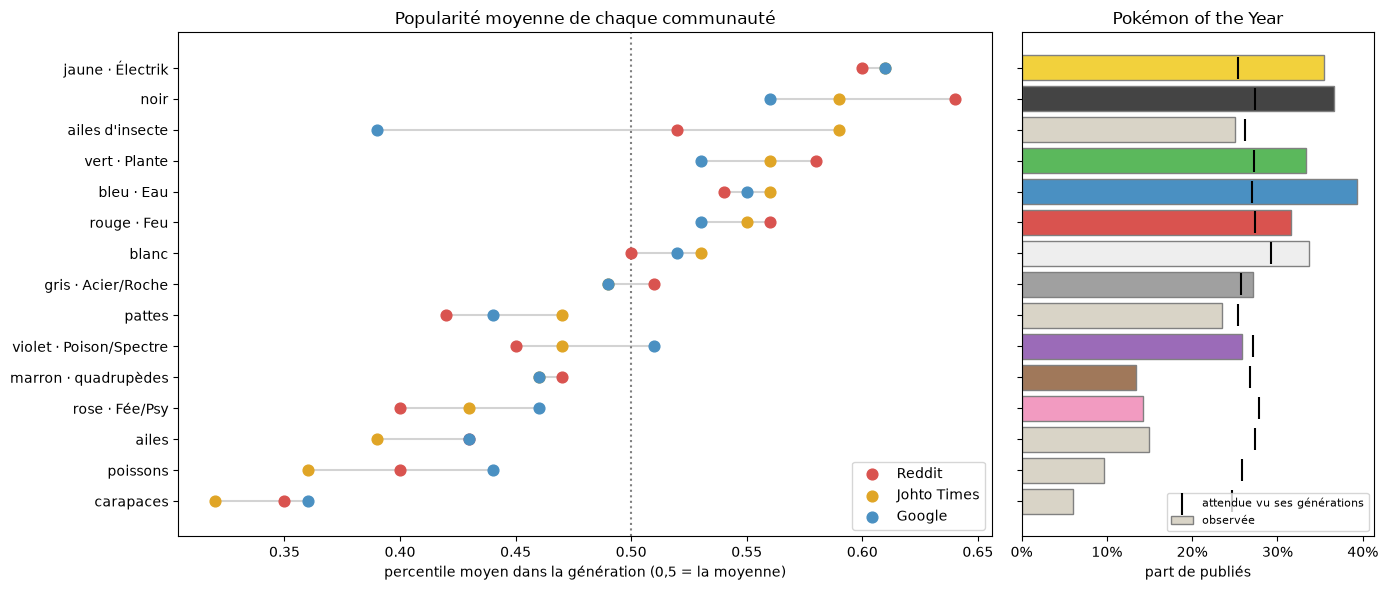

In [20]:
# popularité moyenne de chaque communauté, source par source, et part de publiés à Pokémon of the Year
# (comparée à la part attendue vu la composition de la communauté par génération)
m = moy.rename(index=noms_comm).sort_values("johto")
ordre_comm = list(m.index[::-1])
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True, gridspec_kw={"width_ratios": [3, 1.3]})
for s, nom, coul in [("reddit", "Reddit", "#d9534f"), ("johto", "Johto Times", "#e0a526"), ("trends", "Google", "#4a90c2")]:
    axes[0].scatter(m[s], m.index, s=60, color=coul, label=nom, zorder=3)
axes[0].hlines(m.index, m[["reddit", "johto", "trends"]].min(axis=1), m[["reddit", "johto", "trends"]].max(axis=1), color="lightgrey", zorder=1)
axes[0].axvline(0.5, ls=":", c="grey"); axes[0].legend(loc="lower right")
axes[0].set_xlabel("percentile moyen dans la génération (0,5 = la moyenne)")
axes[0].set_title("Popularité moyenne de chaque communauté")
pc = poty_comm.rename(index=noms_comm).loc[m.index]
axes[1].barh(m.index, pc["part_observee"], color=[COUL_COMM[c] for c in m.index], edgecolor="grey", label="observée")
axes[1].scatter(pc["part_attendue"], m.index, marker="|", s=250, color="black", zorder=3, label="attendue vu ses générations")
axes[1].legend(loc="lower right", fontsize=8)
axes[1].set_xlabel("part de publiés")
axes[1].set_title("Pokémon of the Year")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()

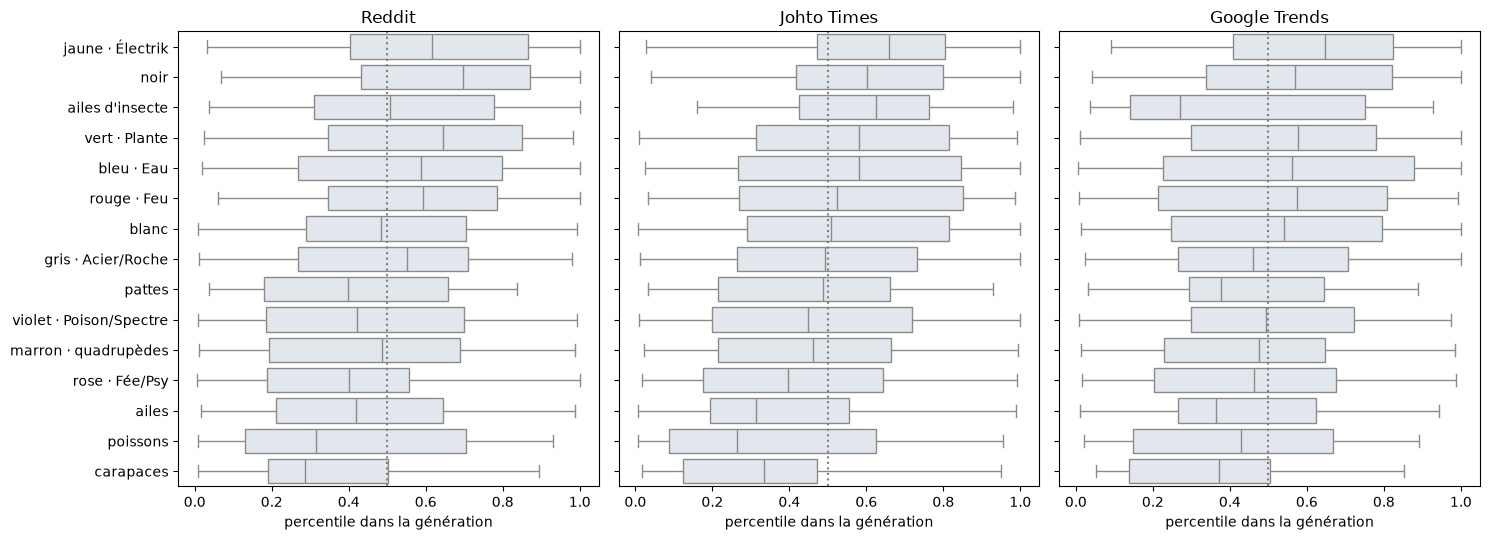

In [21]:
# la même chose avec tout l'étalement : une boîte par communauté (rangées comme au-dessus)
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), sharey=True)
for ax, s, nom in zip(axes, ["reddit", "johto", "trends"], ["Reddit", "Johto Times", "Google Trends"]):
    sns.boxplot(data=dp.assign(nom=dp["communaute"].map(noms_comm)), y="nom", x=s, order=ordre_comm,
                color="#dfe7ef", fliersize=2, ax=ax)
    ax.axvline(0.5, ls=":", c="grey"); ax.set_title(nom); ax.set_xlabel("percentile dans la génération"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

### Ce qu'on a fait et pourquoi

**1. Louvain pour trouver les communautés.** On cherche des groupes de Pokémon très reliés entre eux et peu reliés au reste. Louvain fait ça en maximisant la **modularité** (vu au TP3/TP4), il est rapide, et il n'oblige pas à choisir le nombre de groupes à l'avance, contrairement à un k-means. On l'a fait **pondéré** par la similarité, pour qu'une arête entre deux quasi-jumeaux compte plus qu'une arête « limite ».

**2. Tester la stabilité avec plusieurs graines.** Louvain a une part de hasard. On l'a relancé avec 10 graines et on a comparé les découpages avec l'**ARI** (adjusted Rand index), qui mesure si deux découpages mettent les mêmes Pokémon ensemble (1 = identiques, 0 = pas mieux que le hasard). Comme les découpages se ressemblaient bien, on a gardé la graine 0 pour que ce soit reproductible.

**3. Comparer la modularité à celle d'un graphe aléatoire.** Même un graphe aléatoire a une modularité au-dessus de 0 quand on le découpe au mieux. Pour dire que nos communautés sont « réelles », on compare à la modularité de Louvain sur le graphe aléatoire de même taille.

**4. Décrire les communautés avec un tableau.** Pour chaque communauté, on a regardé les types, la couleur et la forme qui dominent, plus quelques exemples. C'est ce qui nous permet de leur donner un sens (« bleu · Eau », « carapaces »…), sinon ce seraient juste des numéros.

**5. Kruskal-Wallis pour comparer la popularité entre communautés.** On a plus de deux groupes et des percentiles qui ne sont pas normaux, donc on a pris Kruskal-Wallis plutôt qu'une ANOVA. On l'a fait aussi sur les **résidus** du notebook 05 : si l'écart entre communautés disparaît sur les résidus, c'est qu'il passait par les effets déjà connus (type, stade…) et pas par la communauté elle-même. Les boîtes à moustaches par communauté montrent la même chose en image, avec tout l'étalement.

**6. Quelle popularité pour chaque source.** Le percentile **dans la génération** pour les trois sources continues, comme dans les notebooks 04 à 06 : des Pokémon voisins dans le réseau ont souvent des générations proches, et avec un percentile global, une communauté pleine de Pokémon de 1re génération aurait paru « populaire » juste à cause de la nostalgie. Pour Pokémon of the Year, qui est un oui / non (publié ou pas), il faut aussi raisonner dans la génération, parce que la part de publiés vaut à peu près 30 / taille de la génération. On teste donc la communauté **à génération fixée**, avec une régression logistique (publié ~ génération, puis + communauté, test du rapport de vraisemblance). Pour les centralités et l'assortativité, on utilise « publié moins le taux de publication de sa génération ».

**7. Montrer les communautés en images.** Un tableau de pourcentages ne dit pas grand-chose à quelqu'un qui ne connaît pas les Pokémon par cœur. Les portraits (les 8 Pokémon les plus typiques de chaque communauté), les cartes de chaleur couleur/forme et le petit réseau des communautés permettent de voir d'un coup d'œil ce qui fait chaque groupe et lesquels sont proches.

## 4. Centralités et popularité

Pour chaque Pokémon, on calcule (comme au TP3) :
- le **degré** : nombre de voisins. Un Pokémon de fort degré ressemble à beaucoup d'autres (il est « banal ») ; un Pokémon de faible degré n'est le proche voisin de presque personne (il est « original ») ;
- la **similarité moyenne** à ses k voisins : plus elle est basse, plus le Pokémon est isolé dans l'espace des vecteurs ;
- l'**intermédiarité** (betweenness) : est-il sur beaucoup de plus courts chemins, comme un pont entre groupes ;
- la **proximité** (closeness) : est-il proche de tout le monde en moyenne ;
- le **coefficient de clustering** local : ses voisins sont-ils voisins entre eux.

Puis la corrélation de Spearman de chaque centralité avec chaque source de popularité.

In [22]:
cent = pd.DataFrame({
    "degre": dict(G.degree()),
    "similarite_voisins": {n: np.mean([G[n][v]["weight"] for v in G[n]]) for n in G},
    "intermediarite": nx.betweenness_centrality(G, seed=SEED),
    "proximite": nx.closeness_centrality(G),
    "clustering": nx.clustering(G),
})
# pour l'originalité « pure », la similarité aux k plus proches voisins (avant symétrisation)
cent["sim_k_voisins"] = pd.Series(1 - dist[:, 1:K + 1].mean(axis=1), index=noeuds)
cent.describe().round(3)

,degre,similarite_voisins,intermediarite,proximite,clustering,sim_k_voisins
count,1025.000,1025.000,1025.000,1025.000,1025.000,1025.000
mean,13.692,0.608,0.003,0.270,0.326,0.639
std,3.950,0.060,0.002,0.013,0.112,0.082
min,10.000,0.424,0.000,0.222,0.067,0.424
25%,11.000,0.570,0.001,0.263,0.244,0.581
50%,12.000,0.614,0.002,0.271,0.317,0.640
75%,15.000,0.651,0.003,0.278,0.385,0.696
max,31.000,0.743,0.011,0.305,0.800,0.856


La similarité moyenne d'un Pokémon à ses 10 plus proches voisins va de 0,43 (très à part) à 0,86 (il a des quasi-jumeaux).

In [23]:
lignes = []
for c in cent.columns:
    for s in ["reddit", "johto", "trends", "poty", "resid_reddit", "resid_johto", "resid_trends"]:
        v = cent[[c]].join(dp[s]).dropna()
        rho, p = spearmanr(v[c], v[s])
        lignes.append({"centralite": c, "source": s, "rho": rho, "p": p})
res_c = pd.DataFrame(lignes)
# 6 centralités × 7 mesures = 42 tests : on corrige les p-valeurs avec Holm (une étoile = significatif après correction)
from statsmodels.stats.multitest import multipletests
res_c["p_holm"] = multipletests(res_c["p"], method="holm")[1]
print("p < 0,05 avant correction :", (res_c.p < 0.05).sum(), "| après Holm :", (res_c.p_holm < 0.05).sum())
tab = res_c.assign(txt=res_c.rho.round(2).astype(str) + np.where(res_c.p_holm < 0.05, " *", "")).pivot(index="centralite", columns="source", values="txt")
tab[["reddit", "johto", "trends", "poty", "resid_reddit", "resid_johto", "resid_trends"]]

p < 0,05 avant correction : 6 | après Holm : 4


source,reddit,johto,trends,poty,resid_reddit,resid_johto,resid_trends
centralite,,,,,,,
clustering,-0.04,-0.04,-0.12 *,-0.05,-0.03,0.0,-0.05
degre,-0.0,0.05,0.11 *,0.09,-0.04,0.0,0.03
intermediarite,-0.02,-0.0,0.11 *,0.04,-0.02,-0.02,0.04
proximite,-0.01,0.01,0.15 *,0.05,0.01,-0.02,0.07
sim_k_voisins,-0.01,0.04,0.05,0.06,-0.03,0.02,0.01
similarite_voisins,-0.01,0.02,0.03,0.04,-0.02,0.02,-0.0


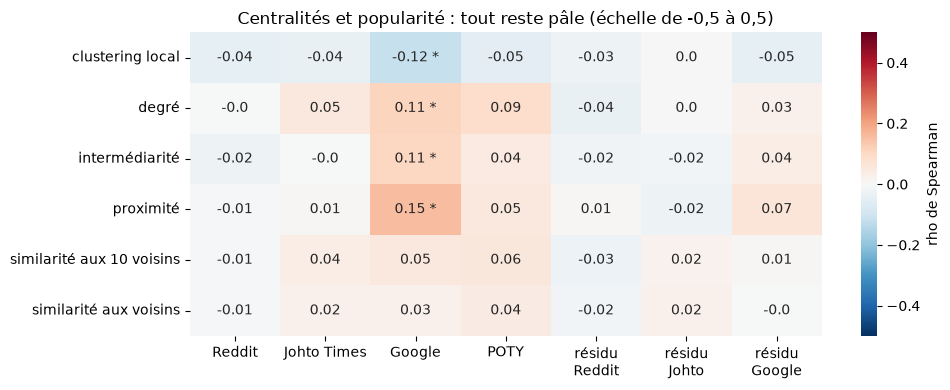

In [24]:
# le même tableau en couleurs : rouge = lien positif, bleu = lien négatif, * = significatif après Holm
ordre = ["reddit", "johto", "trends", "poty", "resid_reddit", "resid_johto", "resid_trends"]
noms_cent = {"degre": "degré", "similarite_voisins": "similarité aux voisins", "intermediarite": "intermédiarité",
             "proximite": "proximité", "clustering": "clustering local", "sim_k_voisins": "similarité aux 10 voisins"}
noms_src = {"reddit": "Reddit", "johto": "Johto Times", "trends": "Google", "poty": "POTY", "resid_reddit": "résidu\nReddit",
            "resid_johto": "résidu\nJohto", "resid_trends": "résidu\nGoogle"}
rho_tab = res_c.pivot(index="centralite", columns="source", values="rho")[ordre].rename(index=noms_cent, columns=noms_src)
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(rho_tab, cmap="RdBu_r", vmin=-0.5, vmax=0.5, annot=tab[ordre].rename(index=noms_cent).values, fmt="",
            cbar_kws={"label": "rho de Spearman"}, ax=ax)
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title("Centralités et popularité : tout reste pâle (échelle de -0,5 à 0,5)")
plt.tight_layout(); plt.show()

Les centralités ne sont **presque pas liées à la popularité** : tous les rho sont entre -0,12 et 0,15, et la carte de chaleur reste pâle. Sur les 42 tests (6 centralités × 7 mesures), 6 ont une p-valeur sous 0,05, mais avec autant de tests on en attend 2 par pur hasard : on corrige donc avec **Holm**, et il en reste 4. Ils sont tous faibles et tous sur Google Trends (proximité 0,15, clustering -0,12, degré 0,11, intermédiarité 0,11). Dans les sondages et pour Pokémon of the Year, aucun ne l'est, et sur les résidus il ne reste rien. (Pour Pokémon of the Year, la proximité ressortait à 0,11 tant qu'on ne tenait pas compte de la génération ; une fois la génération retirée, elle tombe à 0,05 : c'était l'effet des quotas par région.) Être un Pokémon « original » ou « banal » dans ce réseau ne rend ni plus ni moins populaire.

In [25]:
# les plus « originaux » (similarité la plus basse à leurs k voisins) et les plus « banals »
o = cent.join(table[["nom_fr"]]).join(dp[["reddit", "johto", "trends"]]).sort_values("sim_k_voisins")
print("Les plus originaux :"); display(o.head(10)[["nom_fr", "sim_k_voisins", "degre", "reddit", "johto", "trends"]].round(2))
print("Les plus banals :"); display(o.tail(10)[["nom_fr", "sim_k_voisins", "degre", "reddit", "johto", "trends"]].round(2))

Les plus originaux :


,nom_fr,sim_k_voisins,degre,reddit,johto,trends
618,Limonde,0.42,10,0.69,0.27,0.72
101,Électrode,0.44,10,0.11,0.20,NaN
701,Brutalibré,0.45,10,0.92,0.83,0.79
987,Flotte-Mèche,0.45,10,NaN,0.77,0.68
617,Limaspeed,0.45,10,0.59,0.18,0.13
790,Cosmovum,0.45,10,0.03,0.07,0.50
752,Tarenbulle,0.46,10,0.79,0.69,0.14
337,Séléroc,0.46,10,0.21,0.36,0.35
446,Goinfrex,0.46,10,0.66,0.62,0.57
45,Rafflesia,0.46,10,0.62,0.67,0.21


Les plus banals :


,nom_fr,sim_k_voisins,degre,reddit,johto,trends
631,Aflamanoir,0.82,24,0.35,0.13,0.21
396,Étourmi,0.82,25,0.35,0.31,0.80
126,Magmar,0.83,23,0.43,0.30,0.54
467,Maganon,0.83,27,0.49,0.36,0.31
495,Vipélierre,0.83,21,0.87,0.89,0.91
252,Arcko,0.84,23,0.87,0.76,0.73
810,Ouistempo,0.84,22,NaN,0.73,0.75
506,Ponchiot,0.85,27,0.19,0.66,0.47
734,Manglouton,0.85,26,0.01,0.02,0.16
504,Ratentif,0.86,26,0.03,0.05,NaN


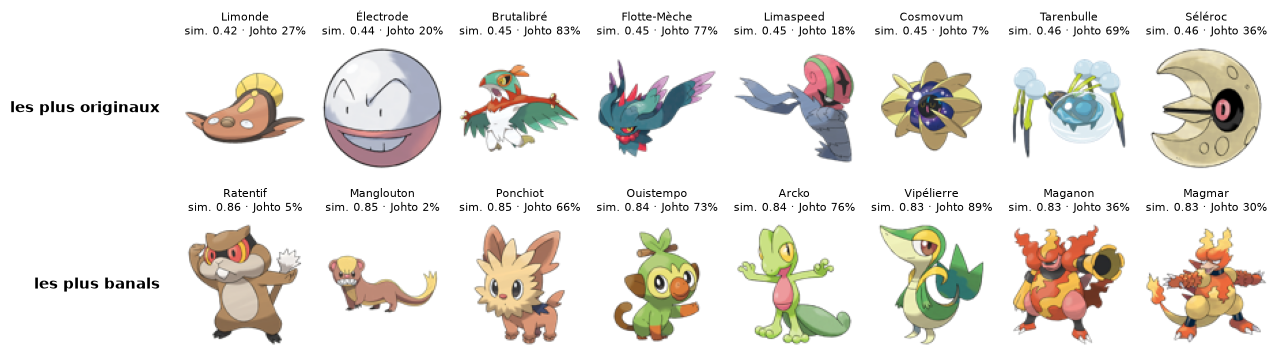

In [26]:
# les mêmes, en images
ext = {"les plus originaux": cent["sim_k_voisins"].nsmallest(8).index,
       "les plus banals": cent["sim_k_voisins"].nlargest(8).index}
fig, axes = plt.subplots(2, 8, figsize=(14, 4.2))
for r, (titre, dexs) in enumerate(ext.items()):
    for ax, dx in zip(axes[r], dexs):
        ax.imshow(sprite_img(dx)); ax.axis("off")
        j = dp.loc[dx, "johto"]
        ax.set_title(f"{table.loc[dx, 'nom_fr']}\nsim. {cent.loc[dx, 'sim_k_voisins']:.2f} · Johto {j:.0%}", fontsize=8)
    axes[r, 0].text(-0.15, 0.5, titre, transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=11, weight="bold")
plt.subplots_adjust(left=0.12, wspace=0.05); plt.show()

Les plus originaux sont des designs qui ne ressemblent à aucune famille : un poisson plat (Limonde), une Poké Ball (Électrode), une lune (Séléroc), un cocon cosmique (Cosmovum)… Leur popularité est très variable : Cosmovum est tout en bas, Brutalibré et Flotte-Mèche sont plutôt aimés. Les plus banals, eux, ont des quasi-jumeaux : des petits mammifères marron (Ratentif, Manglouton, Ponchiot), des starters Plante (Ouistempo, Arcko, Vipélierre) et des Pokémon Feu dressés (Maganon, Magmar). Là aussi, on trouve des Pokémon très aimés (Vipélierre, Arcko) et très peu aimés (Ratentif, Manglouton).

In [27]:
# l'originalité est-elle liée aux effets attendus ? (les légendaires sont peut-être juste plus « à part »)
o2 = cent[["sim_k_voisins", "degre"]].join(table[["legendaire", "fabuleux", "stade_categorie", "generation"]])
display(o2.groupby("stade_categorie")[["sim_k_voisins", "degre"]].mean().round(3))
display(o2.groupby("legendaire")[["sim_k_voisins", "degre"]].mean().round(3))
display(o2.groupby("generation")[["sim_k_voisins", "degre"]].mean().round(3))

,sim_k_voisins,degre
stade_categorie,,
sans évolution,0.620,13.816
stade 1,0.659,14.406
stade 2,0.629,12.793
stade 3,0.646,14.174


,sim_k_voisins,degre
legendaire,,
False,0.639,13.535
True,0.650,15.803


,sim_k_voisins,degre
generation,,
1,0.655,13.967
2,0.648,13.690
3,0.632,13.296
4,0.647,14.131
5,0.637,13.532
6,0.639,13.403
7,0.619,13.955
8,0.635,13.885
9,0.637,13.433


L'originalité ne dépend presque pas du stade, de la génération ou du statut de légendaire : les moyennes sont toutes très proches (0,62 à 0,66). Les légendaires ont même un peu plus de voisins (15,8 contre 13,5).

### Ce qu'on a fait et pourquoi

**1. Plusieurs centralités, parce qu'elles ne disent pas la même chose (TP3).** Le **degré** dit si un Pokémon ressemble à beaucoup d'autres (banal) ou à presque personne (original). La **similarité à ses voisins** dit s'il a des quasi-jumeaux ou s'il est isolé. L'**intermédiarité** dit s'il sert de pont entre des groupes, la **proximité** s'il est au « centre » du réseau, et le **clustering** si ses voisins se ressemblent entre eux. Comme on ne savait pas à l'avance laquelle pourrait jouer sur la popularité, on les a toutes testées.

**2. La similarité aux k voisins « avant symétrisation ».** Dans le graphe, un Pokémon peut gagner des voisins parce que d'autres l'ont choisi. Pour mesurer l'originalité « pure », on a pris la similarité moyenne à ses 10 plus proches voisins à lui, directement depuis les distances.

**3. Spearman avec la popularité, sur les sources et sur les résidus.** Spearman, parce que les centralités sont très asymétriques (l'intermédiarité surtout) et que la popularité est en percentile. Les résidus du notebook 05 servent à vérifier qu'un lien éventuel ne vient pas juste du type ou du stade. Comme on fait 42 tests d'un coup, on corrige les p-valeurs avec **Holm** (comme au notebook 04) : sans ça, quelques « significatifs » sortiraient juste par hasard. L'étoile du tableau veut dire « significatif après correction ».

**4. Regarder les plus originaux et les plus banals.** Un coefficient proche de 0 peut cacher des choses. En listant les Pokémon aux deux extrêmes avec leur popularité, on voit concrètement qu'il y a des aimés et des pas aimés des deux côtés.

**5. Vérifier si l'originalité dépend du stade, de la génération ou des légendaires.** On pouvait penser que les légendaires sont « à part » par nature. On a donc comparé l'originalité moyenne par groupe pour voir si elle ne mesurait pas juste ça.

## 5. Les Pokémon populaires sont-ils voisins de Pokémon populaires ?

C'est l'**assortativité** : si on prend chaque arête, est-ce que les deux bouts ont une popularité proche ? On calcule le coefficient d'assortativité numérique de networkx pour chaque source (sur les Pokémon qui ont une valeur). Pour savoir si la valeur obtenue est grande, on la compare à ce qu'on obtient en **mélangeant la popularité au hasard** entre les Pokémon (test de permutation, 200 tirages).

In [28]:
def assortativite(G, valeurs):
    H = G.subgraph(valeurs.dropna().index).copy()
    nx.set_node_attributes(H, valeurs.dropna().to_dict(), "x")
    return nx.numeric_assortativity_coefficient(H, "x")

rng = np.random.default_rng(SEED)
lignes = []
for s in ["reddit", "johto", "trends", "poty", "resid_reddit", "resid_johto", "resid_trends"]:
    v = dp[s].dropna()
    r_obs = assortativite(G, v)
    r_perm = [assortativite(G, pd.Series(rng.permutation(v.values), index=v.index)) for _ in range(200)]
    lignes.append({"source": s, "assortativite": r_obs, "perm_moyenne": np.mean(r_perm), "perm_max": np.max(r_perm),
                   "p_permutation": (np.sum(np.array(r_perm) >= r_obs) + 1) / 201})
assort = pd.DataFrame(lignes)
assort.set_index("source").round(3)

,assortativite,perm_moyenne,perm_max,p_permutation
source,,,,
reddit,0.156,-0.001,0.039,0.005
johto,0.179,-0.001,0.035,0.005
trends,0.126,-0.001,0.028,0.005
poty,0.100,-0.001,0.033,0.005
resid_reddit,0.021,-0.000,0.040,0.070
resid_johto,0.045,-0.002,0.032,0.005
resid_trends,0.014,-0.002,0.031,0.095


En revanche, les Pokémon populaires **sont plutôt voisins de Pokémon populaires** : l'assortativité vaut 0,16 (Reddit), 0,18 (Johto Times), 0,13 (Google) et 0,10 (Pokémon of the Year, publié ou non par rapport à sa génération). C'est faible, mais bien au-dessus de ce que donne un mélange au hasard (jamais plus de 0,04 en 200 tirages, p = 0,005).

Sur les résidus du notebook 05, l'assortativité tombe à 0,01-0,05, et elle n'est plus significative que pour le Johto Times (0,05, p = 0,005) ; sur Reddit (p = 0,07) et Google (p = 0,10), on ne peut plus la distinguer du hasard. Donc la ressemblance entre voisins populaires vient presque entièrement des effets attendus (même type, même position dans la lignée…).

reddit  rho = 0.345  p = 4.3e-24  (n = 809)


johto   rho = 0.420  p = 4.2e-45  (n = 1025)


trends  rho = 0.313  p = 4e-24  (n = 997)


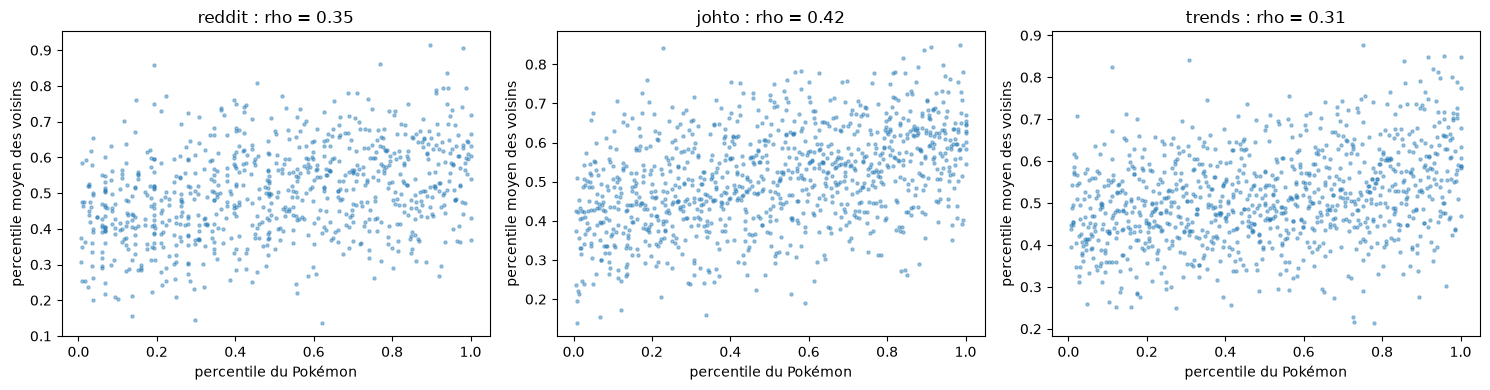

In [29]:
# version plus parlante : la popularité d'un Pokémon contre la popularité moyenne de ses voisins
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, s in zip(axes, ["reddit", "johto", "trends"]):
    v = dp[s]
    moy_v = pd.Series({n: v.reindex(list(G[n])).mean() for n in G})
    w = pd.DataFrame({"soi": v, "voisins": moy_v}).dropna()
    ax.scatter(w.soi, w.voisins, s=5, alpha=.4)
    rho, p = spearmanr(w.soi, w.voisins)
    ax.set_title(f"{s} : rho = {rho:.2f}")
    print(f"{s:7s} rho = {rho:.3f}  p = {p:.2g}  (n = {len(w)})")
    ax.set_xlabel("percentile du Pokémon"); ax.set_ylabel("percentile moyen des voisins")
plt.tight_layout(); plt.show()

Avec la popularité moyenne des voisins, on voit la même chose : rho = 0,35 (Reddit), 0,42 (Johto Times) et 0,31 (Google), tous très significatifs. Le nuage reste très dispersé : avoir des voisins populaires ne garantit rien.

### Ce qu'on a fait et pourquoi

**1. L'assortativité.** La question « est-ce que les populaires sont voisins de populaires ? » se mesure avec le coefficient d'assortativité numérique : pour toutes les arêtes, on regarde si les deux bouts ont une popularité proche. C'est la version « réseau » d'une corrélation entre voisins.

**2. Un test par permutation plutôt qu'une p-valeur toute faite.** On ne sait pas bien quelle valeur l'assortativité prendrait « par hasard » sur un graphe comme le nôtre. Du coup, on a mélangé 200 fois la popularité entre les Pokémon (le graphe ne bouge pas) et recalculé l'assortativité à chaque fois. Si la vraie valeur est au-dessus de presque tous les tirages, ce n'est pas le hasard. C'est simple à comprendre et ça ne suppose rien sur la loi des données.

**3. Refaire le test sur les résidus.** Deux Pokémon voisins ont souvent le même type ou le même stade. Sur les résidus du notebook 05, ces effets sont retirés : si l'assortativité baisse beaucoup, c'est qu'elle venait surtout de là.

**4. Le nuage « popularité du Pokémon / popularité moyenne de ses voisins ».** Le coefficient d'assortativité est un peu abstrait. Ce nuage montre la même idée de façon plus parlante, et surtout il montre la **dispersion** : même avec un lien significatif, avoir des voisins populaires ne garantit rien.

### Et sans la couleur officielle ?

Le vecteur de chaque Pokémon contient deux blocs sur la couleur : la **couleur officielle** de PokéAPI et les **couleurs de l'image** (notebook 03). On a gardé les deux parce qu'elles ne disent pas la même chose (la couleur « d'identité » choisie par les jeux, et la couleur qui couvre le plus de surface). Mais on a vu en partie 3 que les communautés suivent surtout la couleur officielle. On refait donc le réseau **sans ce bloc**, avec exactement les mêmes réglages, pour voir ce qui change et ce qui tient.

In [30]:
blocs_sans = {k: b for k, b in blocs.items() if k != "couleur_off"}
parties = []
for nom, b in blocs_sans.items():
    z = StandardScaler().fit_transform(b.astype(float))
    parties.append(pd.DataFrame(z / np.sqrt(b.shape[1]), index=b.index))
X2 = pd.concat(parties, axis=1).loc[table.index]
dist2, idx2 = NearestNeighbors(metric="cosine").fit(X2.values).kneighbors(X2.values, n_neighbors=K + 1)
G2 = nx.Graph()
G2.add_nodes_from(noeuds)
for i in range(len(noeuds)):
    for j, dd in zip(idx2[i, 1:], dist2[i, 1:]):
        G2.add_edge(noeuds[i], noeuds[j], weight=1 - dd)
comm2 = etiquettes(louvain_communities(G2, weight="weight", seed=SEED))
print(f"sans la couleur officielle : {comm2.nunique()} communautés (contre {comm.nunique()}), "
      f"modularité {modularity(G2, louvain_communities(G2, weight='weight', seed=SEED), weight='weight'):.2f}")
print("accord avec le découpage avec la couleur officielle (ARI) :", round(adjusted_rand_score(comm.loc[noeuds], comm2.loc[noeuds]), 2))
lignes = []
for c in ["reddit", "johto", "trends", "resid_reddit", "resid_johto", "resid_trends"]:
    p_avec = kruskal(*[g[c].dropna() for _, g in dp.groupby("communaute")])[1]
    p_sans = kruskal(*[g[c].dropna() for _, g in dp.join(comm2.rename("c2")).groupby("c2")])[1]
    lignes.append({"mesure": c, "Kruskal p (avec)": p_avec, "Kruskal p (sans)": p_sans,
                   "assortativité (avec)": assortativite(G, dp[c]), "assortativité (sans)": assortativite(G2, dp[c])})
pd.DataFrame(lignes).set_index("mesure").map(lambda v: f"{v:.2g}")

sans la couleur officielle : 18 communautés (contre 15), modularité 0.68
accord avec le découpage avec la couleur officielle (ARI) : 0.19


,Kruskal p (avec),Kruskal p (sans),assortativité (avec),assortativité (sans)
mesure,,,,
reddit,3e-06,7.2e-07,0.16,0.16
johto,7.6e-09,4.4e-10,0.18,0.21
trends,0.00061,2e-09,0.13,0.17
resid_reddit,0.15,0.64,0.021,-0.0035
resid_johto,0.018,0.15,0.045,0.049
resid_trends,0.57,0.46,0.014,0.011


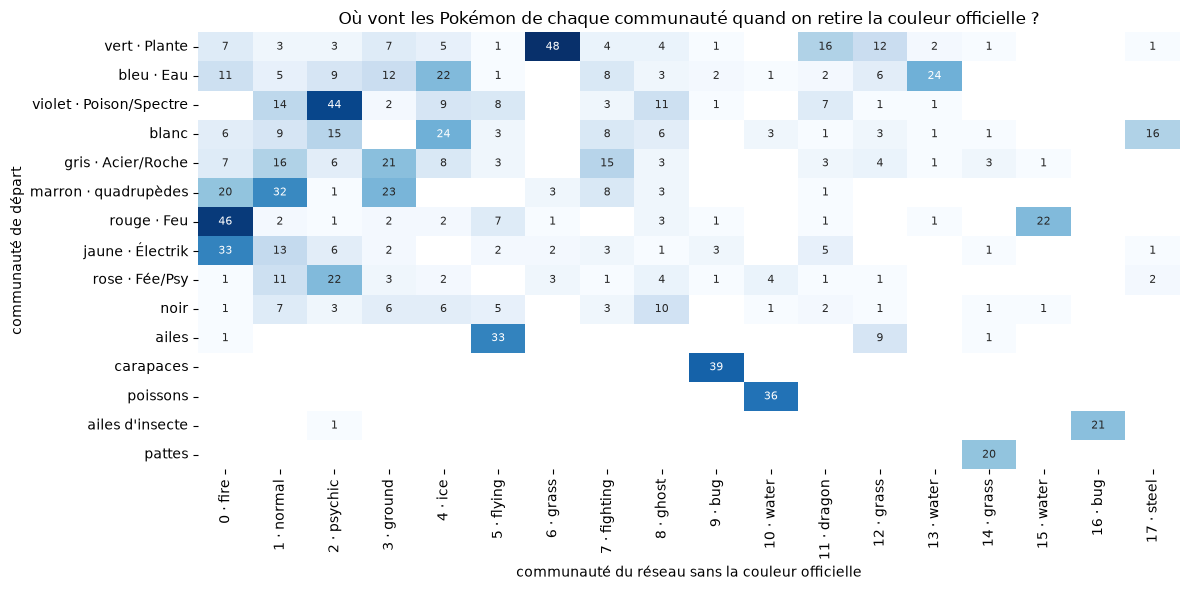

In [31]:
# comment les communautés de départ se répartissent dans le réseau sans couleur officielle
# chaque nouvelle communauté est nommée par son type le plus fréquent (en premier ou en second type)
type_dom = {c: pd.concat([table.loc[g.index, "type1"], table.loc[g.index, "type2"].dropna()]).mode()[0]
            for c, g in comm2.groupby(comm2)}
croise = pd.crosstab(comm.loc[noeuds].map(noms_comm), comm2.loc[noeuds].map(lambda c: f"{c} · {type_dom[c]}").rename("sans"))
croise = croise[sorted(croise.columns, key=lambda x: int(x.split(" ")[0]))]
croise = croise.loc[[noms_comm[c] for c in sorted(noms_comm)]]
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(croise, cmap="Blues", annot=True, fmt="d", mask=croise == 0, cbar=False, annot_kws={"size": 8}, ax=ax)
ax.set_xlabel("communauté du réseau sans la couleur officielle")
ax.set_ylabel("communauté de départ")
ax.set_title("Où vont les Pokémon de chaque communauté quand on retire la couleur officielle ?")
plt.tight_layout(); plt.show()

Le tableau montre ce qui se passe : les **communautés de forme ne bougent pas** (carapaces, poissons, ailes d'insecte, pattes restent entières, les ailes presque), alors que les **communautés de couleur se mélangent**. Sans la couleur officielle, elles se reforment surtout par le type : les rouges et les jaunes partent ensemble dans une communauté « Feu » (0), la violette et la rose dans une « Psy » (2), les marron et les grises dans « Normal » (1) et « Sol » (3). Seule la verte reste en grande partie groupée, parce que la couleur Plante va avec le type Plante.

Sans la couleur officielle, le réseau se découpe **autrement** : 18 communautés au lieu de 15, et un ARI de 0,19 seulement avec le découpage de départ. Les groupes dépendent donc beaucoup de ce bloc, et les noms qu'on leur a donnés (« bleu · Eau », « rose · Fée/Psy »…) ne valent que pour le réseau avec la couleur officielle.

Par contre, **les conclusions sur la popularité tiennent** :
- la popularité diffère toujours entre communautés, et même plus nettement (Kruskal-Wallis, p < 0,001 pour les trois sources ; Google passe de 0,0006 à 2e-09) ;
- les populaires restent voisins de populaires, avec une assortativité égale ou un peu plus forte (0,16 Reddit, 0,21 Johto Times, 0,17 Google) ;
- sur les résidus, l'effet disparaît toujours. Le petit effet qui restait pour le Johto Times (p = 0,018 sur les communautés) n'est plus significatif (p = 0,15) : il dépendait du découpage, on ne le retient pas.

Donc garder la couleur officielle change **la forme** des communautés, pas ce qu'on conclut sur la popularité.

## 6. node2vec et t-SNE

node2vec (TP4) : on fait des **marches aléatoires** dans le graphe, on les traite comme des « phrases » dont les « mots » sont les Pokémon, et **Word2Vec** apprend un vecteur par Pokémon de façon que ceux qui apparaissent dans les mêmes marches aient des vecteurs proches. On a fait les marches à la main (même fonction qu'au TP4).

Pour les réglages, on reste proche de ce qu'on a fait au TP4 :
- **p = q = 1** : des marches aléatoires classiques, sans favoriser ni le retour en arrière ni l'exploration au loin. On n'a pas de raison de préférer l'un ou l'autre ici ;
- **10 marches de 40 pas** par Pokémon : avec un degré moyen autour de 14, une marche de 40 pas a le temps de sortir du voisinage direct, et 10 marches suffisent pour que chaque Pokémon apparaisse souvent ;
- **vecteurs de dimension 16** : on n'a que 1 025 Pokémon, et on veut juste une carte en 2D derrière, donc pas besoin de grands vecteurs ;
- **fenêtre de 5** : Word2Vec considère que deux Pokémon à moins de 5 pas dans une marche sont « dans le même contexte ».

Ensuite, **t-SNE** projette ces vecteurs en 2D pour faire une carte. On garde la **perplexité par défaut (30)** : elle correspond à peu près au nombre de voisins qu'on regarde, et 30 c'est raisonnable pour 1 025 points (ni trop local, ni trop global). On mesure avec la **trustworthiness** si les voisins sur la carte sont bien des voisins dans l'espace d'origine (1 = parfait).

In [32]:
from gensim.models import Word2Vec

def marches_node2vec(G, n_marches=10, longueur=40, p=1.0, q=1.0, seed=0):
    rng = random.Random(seed)
    voisins_de = {u: list(G[u]) for u in G}
    noeuds_, marches = list(G), []
    for _ in range(n_marches):
        rng.shuffle(noeuds_)
        for depart in noeuds_:
            marche = [depart]
            while len(marche) < longueur:
                ns = voisins_de[marche[-1]]
                if len(marche) == 1:
                    marche.append(rng.choice(ns)); continue
                prec = marche[-2]
                poids = [1 / p if x == prec else 1 if G.has_edge(x, prec) else 1 / q for x in ns]
                marche.append(rng.choices(ns, weights=poids)[0])
            marches.append(marche)
    return marches

N2V_DIM, N2V_MARCHES, N2V_LONGUEUR, N2V_P, N2V_Q = 16, 10, 40, 1.0, 1.0
marches = marches_node2vec(G, N2V_MARCHES, N2V_LONGUEUR, N2V_P, N2V_Q, SEED)
phrases = [[str(n) for n in m] for m in marches]
w2v = Word2Vec(phrases, vector_size=N2V_DIM, window=5, min_count=0, sg=1, workers=1, seed=SEED, epochs=5)
N2V = np.array([w2v.wv[str(n)] for n in noeuds])
print(len(marches), "marches | vecteurs :", N2V.shape)

10250 marches | vecteurs : (1025, 16)


10 marches de 40 pas par Pokémon, soit 10 250 marches, et un vecteur de 16 dimensions par Pokémon.

In [33]:
# les voisins dans l'espace node2vec ressemblent-ils à ceux du graphe ?
from sklearn.metrics.pairwise import cosine_similarity
S = cosine_similarity(N2V)
pos = {n: i for i, n in enumerate(noeuds)}
for d in [6, 25, 94, 133, 448]:
    o = np.argsort(-S[pos[d]])[1:7]
    print(f"{table.loc[d, 'nom_fr']:12s} →", ", ".join(table.loc[noeuds[o], "nom_fr"]))

Dracaufeu    → Camérupt, Magmar, Pyroli, Maganon, Aflamanoir, Braségali
Pikachu      → Galvaran, Posipi, Pâtachiot, Voltoutou, Pohm, Miaouss
Ectoplasma   → Mentali, Groret, Salarsen, Wimessir, Avaltout, Mewtwo
Évoli        → Ponchiot, Manglouton, Fouinette, Keunotor, Goupix, Ratentif
Lucario      → Carchacrok, Pingoléon, Pondralugon, Coatox, Laggron, Carmache


Les voisins node2vec ressemblent à ceux du graphe, mais en un peu plus « large » : node2vec regarde aussi les voisins des voisins. Dracaufeu reste avec des Pokémon Feu (Camérupt, Magmar, Pyroli, Maganon…), Pikachu avec des Pokémon jaunes, surtout Électrik (Galvaran, Posipi, Pâtachiot, Voltoutou…), et Lucario se retrouve avec d'autres Pokémon bipèdes et combatifs (Carchacrok, Pingoléon, Coatox…).

In [34]:
TSNE_PERPLEXITE = 30
tsne_n2v = TSNE(n_components=2, perplexity=TSNE_PERPLEXITE, random_state=SEED, init="pca").fit_transform(N2V)
tsne_x = TSNE(n_components=2, perplexity=TSNE_PERPLEXITE, random_state=SEED, init="pca", metric="cosine").fit_transform(X.values)
pd.DataFrame({
    "trustworthiness (10 voisins)": [trustworthiness(N2V, tsne_n2v, n_neighbors=10), trustworthiness(X.values, tsne_x, n_neighbors=10, metric="cosine")],
}, index=["node2vec → t-SNE (vs node2vec)", "vecteurs → t-SNE direct (vs vecteurs)"]).round(3)

,trustworthiness (10 voisins)
node2vec → t-SNE (vs node2vec),0.992
vecteurs → t-SNE direct (vs vecteurs),0.967


Les deux cartes t-SNE préservent très bien les voisinages : trustworthiness de 0,99 pour node2vec → t-SNE et 0,97 pour le t-SNE direct sur les vecteurs. La perplexité de 30 convient donc, on n'a pas besoin d'en tester d'autres.

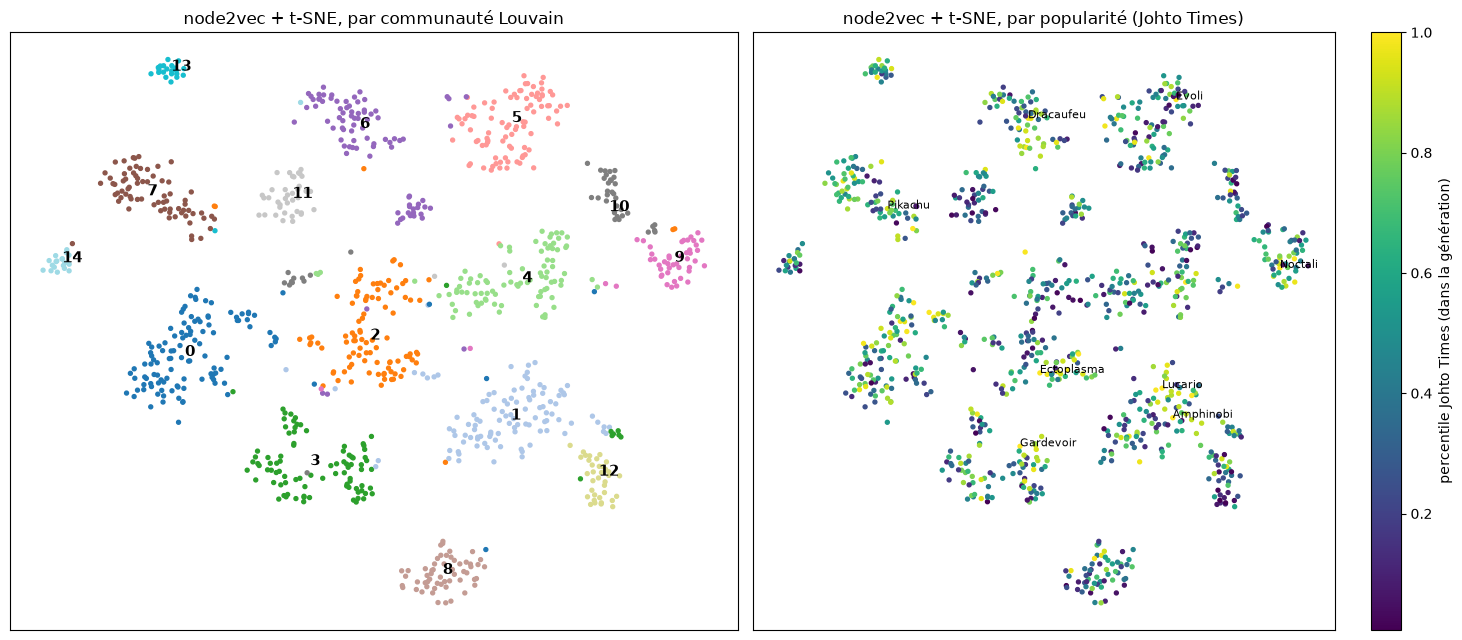

In [35]:
carte = pd.DataFrame(tsne_n2v, index=noeuds, columns=["x", "y"]).join(comm).join(dp[["johto", "reddit", "trends"]]).join(table[["nom_fr"]])
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
sc = axes[0].scatter(carte.x, carte.y, c=carte.communaute, cmap="tab20", s=8)
for c, g in carte.groupby("communaute"):
    axes[0].text(g.x.median(), g.y.median(), str(c), fontsize=11, weight="bold")
axes[0].set_title("node2vec + t-SNE, par communauté Louvain")
sc = axes[1].scatter(carte.x, carte.y, c=carte.johto, cmap="viridis", s=8)
plt.colorbar(sc, ax=axes[1], label="percentile Johto Times (dans la génération)")
for n in [6, 25, 94, 133, 448, 197, 282, 658]:
    axes[1].annotate(table.loc[n, "nom_fr"], (carte.loc[n, "x"], carte.loc[n, "y"]), fontsize=8)
axes[1].set_title("node2vec + t-SNE, par popularité (Johto Times)")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

Sur la carte, les communautés Louvain forment des îlots bien séparés. Dans chaque îlot, la popularité est mélangée (des points clairs et foncés côte à côte), avec par endroits de petits groupes de Pokémon très aimés proches les uns des autres. Ça colle avec l'assortativité faible mais réelle qu'on a mesurée.

### Ce qu'on a fait et pourquoi

**1. node2vec pour passer du graphe à des vecteurs (TP4).** On ne peut pas dessiner directement un graphe de 1 025 nœuds et 7 000 arêtes de façon lisible. node2vec fait des marches aléatoires dans le graphe, les traite comme des phrases, et Word2Vec apprend un vecteur par Pokémon : deux Pokémon qui apparaissent souvent dans les mêmes marches ont des vecteurs proches. L'avantage par rapport aux vecteurs de départ, c'est qu'il tient compte de la **structure du réseau** (les voisins des voisins), pas seulement de la ressemblance directe.

**2. Les réglages.** p = q = 1 donne des marches aléatoires classiques : on n'avait pas de raison de favoriser le retour en arrière ou l'exploration au loin. 10 marches de 40 pas par Pokémon, pour que chacun apparaisse souvent et que les marches sortent du voisinage direct. Des vecteurs de dimension 16, parce qu'on n'a que 1 025 Pokémon et qu'on veut juste une carte derrière. On a gardé des réglages proches du TP4, et une graine fixe pour pouvoir refaire exactement le même résultat.

**3. Vérifier les voisins node2vec.** Comme pour le graphe, on a regardé les voisins de quelques Pokémon connus : si node2vec avait tout mélangé, la carte qui suit ne voudrait rien dire.

**4. t-SNE pour la carte en 2D.** On a choisi t-SNE plutôt qu'une PCA pour la carte, parce que t-SNE garde surtout les **voisinages** (qui est proche de qui), ce qui est exactement ce qui compte dans un réseau de ressemblance. Une PCA garde les grandes directions de variance, mais écrase souvent les petits groupes les uns sur les autres. On a gardé la perplexité par défaut (30), qui correspond à peu près au nombre de voisins regardés.

**5. Mesurer la qualité de la carte avec la trustworthiness.** Avec t-SNE, il faut vérifier que les voisins sur la carte sont bien des voisins dans l'espace de départ. La trustworthiness mesure ça (1 = parfait). On l'a calculée pour node2vec → t-SNE et pour un t-SNE direct sur les vecteurs, pour comparer les deux chemins.

**6. Deux cartes côte à côte.** La même carte colorée une fois par communauté Louvain et une fois par popularité. Ça permet de voir d'un coup d'œil si les communautés forment des îlots, et si la popularité se regroupe dans certains coins ou est mélangée partout. Quelques Pokémon connus sont annotés pour se repérer.

## 7. Export

In [36]:
noeuds_df = table[["nom_fr", "nom_en", "generation", "type1", "type2"]].join(comm).join(cent).join(
    pd.DataFrame(tsne_n2v, index=noeuds, columns=["tsne_x", "tsne_y"]))
noeuds_df.index.name = "dex"
aretes = pd.DataFrame([(u, v, w) for u, v, w in G.edges(data="weight")], columns=["source", "cible", "similarite"])
noeuds_df.to_csv(OUT / "reseau_noeuds.csv")
aretes.to_csv(OUT / "reseau_aretes.csv", index=False)
print(noeuds_df.shape, aretes.shape)

(1025, 14) (7017, 3)


Exports : 1 025 nœuds (communauté, centralités, coordonnées t-SNE) et 7 017 arêtes (avec la similarité), pour le graphe interactif dans Dash.

On exporte aussi les résultats intermédiaires pour pouvoir montrer la méthode dans le dashboard : l'effet de k, la comparaison avec le graphe aléatoire, les communautés et leur popularité, les tests et la stabilité de Louvain. Pour les communautés, on leur donne un petit nom d'après ce qu'on a vu dans le tableau de la section 3 (couleur ou forme qui domine).

In [37]:
# l'effet de k sur le graphe
effet_k.rename(columns={"degre moyen": "degre_moyen"})[["k", "composantes", "aretes", "degre_moyen"]].to_csv(OUT / "methode_07_k.csv", index=False)

# petit monde : notre graphe contre le graphe aléatoire de même taille
mod_reseau = modularity(G, communautes, weight="weight")
petit_monde = pd.DataFrame({
    "mesure": ["clustering", "chemin moyen", "diamètre", "modularité Louvain"],
    "reseau": [comparaison.loc["clustering moyen", "Pokémon (kNN)"], comparaison.loc["plus court chemin moyen (LCC)", "Pokémon (kNN)"],
               comparaison.loc["diamètre (LCC)", "Pokémon (kNN)"], mod_reseau],
    "aleatoire": [comparaison.loc["clustering moyen", "Aléatoire G(n,m)"], comparaison.loc["plus court chemin moyen (LCC)", "Aléatoire G(n,m)"],
                  comparaison.loc["diamètre (LCC)", "Aléatoire G(n,m)"], mod_rand]})
petit_monde.to_csv(OUT / "methode_07_petit_monde.csv", index=False)

# les communautés, avec un nom lisible et la popularité moyenne (mêmes mesures que plus haut)
# (les noms sont définis en section 3)
assert set(noms_comm) == set(moy.index), "le nombre de communautés a changé : relire le tableau de la section 3 et renommer"
comm_df = moy[["n", "reddit", "johto", "trends"]].rename(columns={"n": "taille"}).rename_axis("communaute").reset_index()
comm_df.insert(2, "nom", comm_df["communaute"].map(noms_comm))
comm_df.to_csv(OUT / "methode_07_communautes.csv", index=False)

# Kruskal-Wallis, centralités, assortativité
pd.DataFrame(kw).to_csv(OUT / "methode_07_kruskal.csv", index=False)
res_c.rename(columns={"p": "p_valeur"}).to_csv(OUT / "methode_07_centralites.csv", index=False)   # avec p_holm
assort.rename(columns={"source": "mesure", "perm_max": "max_hasard", "p_permutation": "p_valeur"})[
    ["mesure", "assortativite", "max_hasard", "p_valeur"]].to_csv(OUT / "methode_07_assortativite.csv", index=False)

# stabilité de Louvain selon la graine
pd.DataFrame({"graine": list(essais), "nb_communautes": [len(c) for c in essais.values()],
              "modularite": [modularity(G, c, weight="weight") for c in essais.values()],
              "ari_vs_graine0": [adjusted_rand_score(labs[0], labs[s]) for s in essais]}).to_csv(OUT / "methode_07_louvain_graines.csv", index=False)
print(sorted(f.name for f in OUT.glob("methode_07_*.csv")))
comm_df

['methode_07_assortativite.csv', 'methode_07_centralites.csv', 'methode_07_communautes.csv', 'methode_07_k.csv', 'methode_07_kruskal.csv', 'methode_07_louvain_graines.csv', 'methode_07_petit_monde.csv']


,communaute,taille,nom,reddit,johto,trends
0,0,115,vert · Plante,0.58,0.56,0.53
1,1,106,bleu · Eau,0.54,0.56,0.55
2,2,101,violet · Poison/Spectre,0.45,0.47,0.51
3,3,96,blanc,0.50,0.53,0.52
4,4,91,gris · Acier/Roche,0.51,0.49,0.49
5,5,91,marron · quadrupèdes,0.47,0.46,0.46
6,6,89,rouge · Feu,0.56,0.55,0.53
7,7,72,jaune · Électrik,0.60,0.61,0.61
8,8,56,rose · Fée/Psy,0.40,0.43,0.46
9,9,47,noir,0.64,0.59,0.56
